# Notebook 06 — Hotspots

Notebook 05 told me that income, and the things that travel with it, account for most of the difference in healthy life expectancy between areas. Seven measures predict HLE to within about a year and a half. That's the broad picture, and it's mostly what I expected.

But the broad picture isn't what drew me into this. It was the neighbours: places that share a boundary and differ by 14 to 16 years. So this notebook stops looking at all 660 areas at once and zooms in on the five places where the big gaps cluster together. I want to see what sets the two sides apart, whether the pattern holds inside each local authority, and what these places look like up close. Then I get them ready to view in 3D, where height can show the drop from one area to the next.

## Setting up

I read the saved tables from Notebooks 03 to 05 and change none of them. Everything this notebook makes goes to the Hotspots folder and overwrites on each run.

In [1]:
from pathlib import Path
import sys
import json
import textwrap

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from IPython.display import display
from IPython.display import HTML

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

%matplotlib inline


# Find the project from the notebook's current folder. My working copy uses Data/, the GitHub copy uses data/.
project_folder = next(p for p in [Path.cwd(), *Path.cwd().parents]
                      if (p / "Data/Cleaned/Wide/msoa_wide_660.csv").is_file()
                      or (p / "data/cleaned/Wide/msoa_wide_660.csv").is_file())

data_folder = project_folder / ("Data" if (project_folder / "Data").is_dir() else "data")


# In the GitHub copy the first folder is lowercase (data/raw, data/cleaned), so I lower it to match.
def project_data(relative_path):
    parts = Path(relative_path).parts
    if data_folder.name == "data":
        parts = (parts[0].lower(), *parts[1:])
    return data_folder.joinpath(*parts)


# Enforce the project environment in the working copy. A GitHub clone has no bundled .venv.
expected_environment = project_folder / "VS_CODE/.venv"

if expected_environment.is_dir():
    assert Path(sys.prefix).resolve() == expected_environment.resolve(), "Select the project virtual environment."


# Raw source files sit in the project's raw folder, wherever the project is copied.
def raw_file(filename):
    candidates = sorted(project_data("Raw").rglob(filename))
    if not candidates:
        raise FileNotFoundError(f"Raw source not found in the project's raw folder: {filename}")
    return candidates[0]


output_folder = project_data("Cleaned/Hotspots")

figure_folder = project_data("Cleaned/Hotspots/figures")

figure_folder.mkdir(parents=True, exist_ok=True)

SEED = 42
EXPECTED_AREAS = 660
EXPECTED_MODEL_AREAS = 654
HLE_FLOOR = 50
HLE_COLOURS = ["#46327e", "#365c8d", "#21918c", "#5ec962", "#d7e75b"]
HLE_BREAKS = [55, 60, 65, 70]
HLE_BAND_LABELS = ["<55", "55–<60", "60–<65", "65–<70", "≥70"]

# A low camera. Each view looks from the side where the lower-HLE areas are, so they sit in front and the higher areas rise behind them.
VIEW_ELEVATION = 45
VIEW_AZIMUTH = "from the lower-HLE side"


def read_csv(relative):
    return pd.read_csv(project_data(relative))


# Same pattern as Notebook 05: write the file, read it back, check it matches.
def save_csv(table, filename, index=False):
    path = output_folder / filename
    with path.open("w", encoding="utf-8", newline="") as stream:
        table.to_csv(stream, index=index)
    check = pd.read_csv(path)
    expected = table.reset_index() if index else table.reset_index(drop=True)
    pd.testing.assert_frame_equal(check, expected, check_dtype=False)


def save_figure(figure, filename):
    path = figure_folder / filename
    figure.savefig(path, bbox_inches="tight")
    assert path.is_file() and path.stat().st_size > 0
    plt.show()
    plt.close(figure)


sns.set_theme(style="whitegrid", font_scale=1.0)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150,
                     "axes.spines.top": False, "axes.spines.right": False})

pd.set_option("display.max_columns", None)

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__}")
print("I save to:", output_folder.relative_to(project_folder).as_posix())

Python 3.14.7 | pandas 3.0.6
I save to: Data/Cleaned/Hotspots


### The inputs

The same seven measures as Notebook 05, and the same six city and town centres sitting out, because they have no usable crime figure. They stay on the maps, hatched grey.

From Notebook 05 I also bring each area's prediction, made by a model that never saw the area's own local authority, and its residual: actual HLE minus that prediction, so positive means better than expected. Each area keeps its Notebook 05 group too.

HLE covers 2019 to 2023. The table below keeps each measure's own period and units.

In [2]:
# The wide table from Notebook 03: one row per area, with every measure joined on the area code.
wide = read_csv("Cleaned/Wide/msoa_wide_660.csv").sort_values("area_code").reset_index(drop=True)
assert len(wide) == EXPECTED_AREAS and wide["area_code"].is_unique

# The seven measures I chose in Notebook 03, one for each theme.
review = read_csv("Cleaned/Wide/theme_representatives_for_review.csv")
representatives = review.loc[review["decision"].eq("Provisional representative")].copy()
features = representatives["measure"].tolist()
assert len(features) == 7 and len(set(features)) == 7

In [3]:
# An area must belong to one authority, even when the lookup has several smaller areas underneath it.
lookup = read_csv("Prepared/Geography/ons_lsoa21_to_msoa21_lad22_exploratory_west_midlands.csv")

lookup = lookup[["MSOA21CD", "LAD22CD", "LAD22NM"]].drop_duplicates()
assert lookup.notna().all().all()
assert lookup.groupby("MSOA21CD").size().eq(1).all()

authority_lookup = lookup.rename(columns={"MSOA21CD": "area_code",
                                          "LAD22CD": "authority_code",
                                          "LAD22NM": "authority_name"})

areas = wide.merge(authority_lookup, on="area_code", how="left", validate="one_to_one")
assert (len(areas) == EXPECTED_AREAS
        and areas[["authority_code", "authority_name"]].notna().all().all())

In [4]:
# Notebook 05's results for each area: its group, its out-of-fold prediction and the residual.
ml = read_csv("Cleaned/Machine Learning/area_ml_results.csv")
assert len(ml) == EXPECTED_AREAS and ml["area_code"].is_unique
assert set(ml["area_code"]) == set(areas["area_code"])

# Before joining, both tables must agree on each area's authority and name.
ml_by_code = ml.set_index("area_code").reindex(areas["area_code"])
assert np.array_equal(ml_by_code["authority_code"].to_numpy(), areas["authority_code"].to_numpy())
assert np.array_equal(ml_by_code["authority_name"].to_numpy(), areas["authority_name"].to_numpy())
assert np.array_equal(ml_by_code["local_area_name"].to_numpy(), areas["local_area_name"].to_numpy())

ml_columns = ["cluster_id", "cluster_label", "out_of_fold_prediction", "residual"]

areas = areas.merge(ml[["area_code", *ml_columns]], on="area_code", how="left", validate="one_to_one")

# The six visitor hubs have no crime rate, so they sit outside the model but stay on the map.
excluded = areas["crime_for_analysis"].isna()
assert excluded.sum() == EXPECTED_AREAS - EXPECTED_MODEL_AREAS
assert areas.loc[excluded, "visitor_hub"].all()
assert areas.loc[excluded, ml_columns].isna().all().all()

model_areas = areas.loc[~excluded].copy()
assert len(model_areas) == EXPECTED_MODEL_AREAS
assert model_areas[[*features, "hle_average", *ml_columns]].notna().all().all()
assert np.allclose(model_areas["residual"],
                   model_areas["hle_average"] - model_areas["out_of_fold_prediction"])

In [5]:
# Notebook 05's weights, plus each measure's label, unit and period for the tables below.
coefficients_05 = read_csv("Cleaned/Machine Learning/coefficients.csv")
assert coefficients_05["measure"].is_unique and set(coefficients_05["measure"]) == set(features)

feature_dictionary = read_csv("Cleaned/Wide/data_dictionary.csv").set_index("column")
feature_labels = representatives.set_index("measure")["label"].to_dict()
feature_units = feature_dictionary.loc[features, "unit"].to_dict()

measure_table = representatives[["measure", "label"]].copy()
measure_table["unit"] = measure_table["measure"].map(feature_units)
measure_table["period"] = measure_table["measure"].map(feature_dictionary["period"])

In [6]:
# Notebook 04's neighbour pairs and its 95 big-gap pairs. Each pair is stored once, smaller code first.
big_pairs = read_csv("Cleaned/Neighbours/big_gap_pairs.csv")
neighbour_pairs = read_csv("Cleaned/Neighbours/neighbour_pairs.csv")
assert len(big_pairs) == 95 and len(neighbour_pairs) == 1885
area_by_code = areas.set_index("area_code")

# I recalculate every saved gap from the HLE values, so a stale file can't slip through.
for table in [big_pairs, neighbour_pairs]:
    assert not table.duplicated(["area_a", "area_b"]).any()
    assert set(table["area_a"]) | set(table["area_b"]) <= set(areas["area_code"])
    assert table["area_a"].lt(table["area_b"]).all()
    assert np.allclose(table["gap_years"],
                       (table["area_a"].map(area_by_code["hle_average"])
                        - table["area_b"].map(area_by_code["hle_average"])).abs())

# Every big-gap pair must also be a neighbour pair.
assert (set(zip(big_pairs["area_a"], big_pairs["area_b"]))
        <= set(zip(neighbour_pairs["area_a"], neighbour_pairs["area_b"])))

In [7]:
# British National Grid (EPSG:27700) works in metres, so lengths and margins below are in metres too.
boundaries = gpd.read_file(raw_file("ons_msoa21_boundaries_exploratory_west_midlands.geojson")).to_crs(27700)
assert boundaries["MSOA21CD"].is_unique and set(boundaries["MSOA21CD"]) == set(areas["area_code"])

map_areas = (boundaries[["MSOA21CD", "geometry"]]
             .rename(columns={"MSOA21CD": "area_code"})
             .merge(areas, on="area_code", how="left", validate="one_to_one")
             .set_index("area_code")
             .sort_index())
assert map_areas.geometry.is_valid.all() and not map_areas.geometry.is_empty.any()

In [8]:
# Census shares are added, not averaged, so the six groups retain the whole ethnic composition.
ethnicity_sources = {
    "white_british_pct": ["white_british_pct"],
    "other_white_pct": ["white_irish_pct", "white_gypsy_irish_traveller_pct", "white_roma_pct", "white_other_pct"],
    "asian_pct": [c for c in wide if c.startswith("asian_")],
    "black_pct": [c for c in wide if c.startswith("black_")],
    "mixed_pct": [c for c in wide if c.startswith("mixed_")],
    "other_pct": ["other_arab_pct", "other_ethnic_group_pct"]}

ethnicity_labels = {"white_british_pct": "White British", "other_white_pct": "Other White",
                    "asian_pct": "Asian", "black_pct": "Black", "mixed_pct": "Mixed", "other_pct": "Other"}

ethnicity_columns = list(ethnicity_sources)
assert len({c for source in ethnicity_sources.values() for c in source}) == 19

for column, source in ethnicity_sources.items():
    assert map_areas[source].notna().all().all()
    map_areas[column] = map_areas[source].sum(axis=1)

# Each area's six groups should add back up to 100%.
assert np.allclose(map_areas[ethnicity_columns].sum(axis=1), 100, atol=0.1, rtol=0)


# At each cutoff the value moves into the next band, just as in the dashboard's color() function.
map_areas["hle_band"] = np.searchsorted(HLE_BREAKS, map_areas["hle_average"], side="right") + 1

map_areas["hle_colour"] = map_areas["hle_band"].map(dict(enumerate(HLE_COLOURS, start=1)))

display(measure_table.reset_index(drop=True))
print(f"I use {len(model_areas)} areas for the measures and retain all {len(map_areas)} on the map.")

,measure,label,unit,period
0,annual_equivalised_income_after_housing_costs_gbp,Household income after housing costs,£ per year,FYE March 2023
1,level4plus_pct,Level 4+ qualifications,% residents aged 16+,2021
2,crime_for_analysis,Recorded crime (visitor hubs omitted),"published rows / 1,000 residents",2024 / population 2021
3,fuel_poor_households_pct,Fuel-poor households,% households,2024
4,no2_area_mean_ug_m3,NO₂ area mean,µg/m³,2024
5,employed_residents_16plus_pct,Employed residents aged 16+,% residents aged 16+,2021
6,asb_rows_per_1000_residents,Anti-social behaviour rate,"published rows / 1,000 residents",2024 / population 2021


I use 654 areas for the measures and retain all 660 on the map.


## 1. Finding the hotspots

One big-gap pair on its own could be a quirk of two estimates. A patch where big gaps keep turning up is a place where the difference is real and repeated.

I treat each area as a point and each of the 95 big-gap pairs as a link between two points. Areas joined by links, directly or through a chain, form one patch. I rank the patches by their number of big-gap pairs, breaking ties by the largest gap in the patch. The top five are the hotspots.

Neighbours share more than one metre of boundary; touching at a corner doesn't count. The big-gap rule keeps the top 5% of neighbour gaps whose gap divided by its estimated uncertainty is above 1.96.

In [9]:
# Working names for the five largest patches, and the areas I expect in each.
# If the data ever changed, the checks further down would stop the notebook rather than mislabel a patch.
HOTSPOT_NAMES = {
    1: "Chelmsley Wood and Castle Bromwich",
    2: "Frankley and Bartley Green",
    3: "Druids Heath and Wythall",
    4: "Kingstanding and New Oscott",
    5: "Yardley Wood and Fox Hollies"}

expected_names = [
    {"Castle Bromwich East", "Chelmsley Wood East", "Chelmsley Wood West", "Coleshill", "Fordbridge",
     "Marston Green", "Shard End", "Smith's Wood North", "Smith's Wood South"},
    {"Allens Cross", "Bartley Green", "Dodford", "Frankley", "Halesowen East", "Rubery West", "Woodgate",
     "Woodgate Valley"},
    {"Alvechurch", "Church Hill South", "Druids Heath", "Hawkesley", "Hollywood", "Wythall"},
    {"Kingstanding North", "Kingstanding South East", "New Oscott", "Perry Common College Road", "Short Heath"},
    {"Fox Hollies", "Solihull Lodge", "Ulverley Green", "Yardley Wood East", "Yardley Wood West"}]

In [10]:
# Grouping linked pairs into patches. Every area starts as its own group, pointing to itself.
# Each big-gap pair joins two groups. Joining two roots joins their whole chains,
# so I don't need a graph library for this.
parent = {c: c for c in set(big_pairs["area_a"]) | set(big_pairs["area_b"])}


# Follow the pointers up to the group's root. Pointing each step at its grandparent keeps the chains short.
def find_root(code):
    while parent[code] != code:
        parent[code] = parent[parent[code]]
        code = parent[code]
    return code


for a, b in zip(big_pairs["area_a"], big_pairs["area_b"]):
    parent[find_root(a)] = find_root(b)

# Areas sharing a root form one patch.
components = {}

for area_code in sorted(parent):
    components.setdefault(find_root(area_code), []).append(area_code)

patches = []

for codes in components.values():
    patch_pairs = big_pairs.loc[big_pairs["area_a"].isin(codes)]
    assert patch_pairs["area_b"].isin(codes).all()
    patches.append({"codes": codes, "pair_count": len(patch_pairs),
                    "largest_gap_years": float(patch_pairs["gap_years"].max())})

# Most pairs first; the largest gap breaks ties, then the first code, so the order never shifts.
patches.sort(key=lambda p: (-p["pair_count"], -p["largest_gap_years"], min(p["codes"])))
assert len(patches) == 45 and sum(p["pair_count"] == 1 for p in patches) == 24

In [11]:
# The top five patches become the hotspots. Their members and sizes must match what I expect.
hotspot_codes = {}

for hotspot_id, patch in enumerate(patches[:5], start=1):
    actual_names = set(area_by_code.loc[patch["codes"], "local_area_name"])
    assert actual_names == expected_names[hotspot_id - 1], f"Hotspot {hotspot_id} differs: {sorted(actual_names)}"
    assert len(patch["codes"]) == [9, 8, 6, 5, 5][hotspot_id - 1]
    assert patch["pair_count"] == [9, 7, 5, 4, 4][hotspot_id - 1]
    hotspot_codes[hotspot_id] = patch["codes"]

# Hotspots 4 and 5 tie on pairs, so the largest gap decides their order.
assert np.isclose(patches[3]["largest_gap_years"], 15.85)
assert np.isclose(patches[4]["largest_gap_years"], 15.65)

hotspot_lookup = {c: h for h, codes in hotspot_codes.items() for c in codes}

big_pairs["hotspot_id"] = big_pairs["area_a"].map(hotspot_lookup).astype("Int64")
assert big_pairs["hotspot_id"].equals(big_pairs["area_b"].map(hotspot_lookup).astype("Int64"))

# Does each pair cross a local authority boundary?
for table in [big_pairs, neighbour_pairs]:
    table["crosses_authority"] = (table["area_a"].map(area_by_code["authority_code"])
                                  .ne(table["area_b"].map(area_by_code["authority_code"])))

In [12]:
# One row per hotspot: its size, its authorities, and where it sits on the map for the web views.
hotspot_rows = []

for hotspot_id, codes in hotspot_codes.items():
    selected = map_areas.loc[codes]

    # The centroid is worked out in metres, then converted to longitude and latitude.
    geometry = selected.geometry.union_all()
    centroid = gpd.GeoSeries([geometry.centroid], crs=27700).to_crs(4326).iloc[0]
    west, south, east, north = selected.to_crs(4326).total_bounds

    patch_pairs = big_pairs.loc[big_pairs["hotspot_id"].eq(hotspot_id)]
    hotspot_rows.append({"hotspot_id": hotspot_id, "working_name": HOTSPOT_NAMES[hotspot_id],
        "area_count": len(codes), "pair_count": len(patch_pairs),
        "largest_gap_years": float(patch_pairs["gap_years"].max()),
        "authorities": "; ".join(sorted(selected["authority_name"].unique())),
        "centroid_longitude": float(centroid.x), "centroid_latitude": float(centroid.y),
        "bbox_west": float(west), "bbox_south": float(south), "bbox_east": float(east), "bbox_north": float(north)})

hotspots = pd.DataFrame(hotspot_rows)

hotspot_pair_table = big_pairs.loc[big_pairs["hotspot_id"].notna()].copy()

In [13]:
# How often pairs cross a council boundary: each hotspot, then the wider sets to compare against.
crossing_rows = []

for hotspot_id in HOTSPOT_NAMES:
    subset = hotspot_pair_table.loc[hotspot_pair_table["hotspot_id"].eq(hotspot_id)]
    crossing_rows.append({"scope": HOTSPOT_NAMES[hotspot_id], "pair_count": len(subset),
        "cross_authority_count": int(subset["crosses_authority"].sum()),
        "cross_authority_share": float(subset["crosses_authority"].mean())})

for scope, subset in [("Five hotspots together", hotspot_pair_table),
                      ("All big-gap pairs", big_pairs),
                      ("All neighbour pairs", neighbour_pairs)]:
    crossing_rows.append({"scope": scope, "pair_count": len(subset),
        "cross_authority_count": int(subset["crosses_authority"].sum()),
        "cross_authority_share": float(subset["crosses_authority"].mean())})

authority_crossing = pd.DataFrame(crossing_rows)

display(hotspots[["working_name", "area_count", "pair_count", "largest_gap_years", "authorities"]].round(2))

display(authority_crossing
        .assign(cross_authority_share=lambda t: (100 * t["cross_authority_share"]).round(1))
        .rename(columns={"cross_authority_share": "Cross-authority %"}))

print(f"I find {len(patches)} patches, with {sum(p['pair_count'] == 1 for p in patches)} single-pair patches.")

,working_name,area_count,pair_count,largest_gap_years,authorities
0,Chelmsley Wood and Castle Bromwich,9,9,12.30,Birmingham; North Warwickshire; Solihull
1,Frankley and Bartley Green,8,7,15.15,Birmingham; Bromsgrove; Dudley
2,Druids Heath and Wythall,6,5,15.55,Birmingham; Bromsgrove; Redditch
3,Kingstanding and New Oscott,5,4,15.85,Birmingham
4,Yardley Wood and Fox Hollies,5,4,15.65,Birmingham; Solihull


,scope,pair_count,cross_authority_count,Cross-authority %
0,Chelmsley Wood and Castle Bromwich,9,5,55.6
1,Frankley and Bartley Green,7,7,100.0
2,Druids Heath and Wythall,5,5,100.0
3,Kingstanding and New Oscott,4,0,0.0
4,Yardley Wood and Fox Hollies,4,2,50.0
5,Five hotspots together,29,19,65.5
6,All big-gap pairs,95,37,38.9
7,All neighbour pairs,1885,465,24.7


I find 45 patches, with 24 single-pair patches.


The five hotspots bring together 29 big-gap pairs and 33 areas. Four involve more than one authority. Frankley and Bartley Green, and Druids Heath and Wythall, have every big-gap pair crossing an authority boundary. Kingstanding and New Oscott is entirely inside Birmingham.

Across the hotspots, 19 of 29 pairs cross authorities (65.5%). Across all big-gap pairs it's 37 of 95 (38.9%), against 465 of 1885 ordinary neighbour pairs (24.7%). Council boundaries turn up more often among the big gaps, and more often still in these patches. But the Kingstanding patch shows that the divide can sit inside one council too.

### The five on the whole map

The light grey areas show the full study area. The five coloured patches are the hotspots, numbered in the same order as the table. Thin grey lines mark the local authorities.

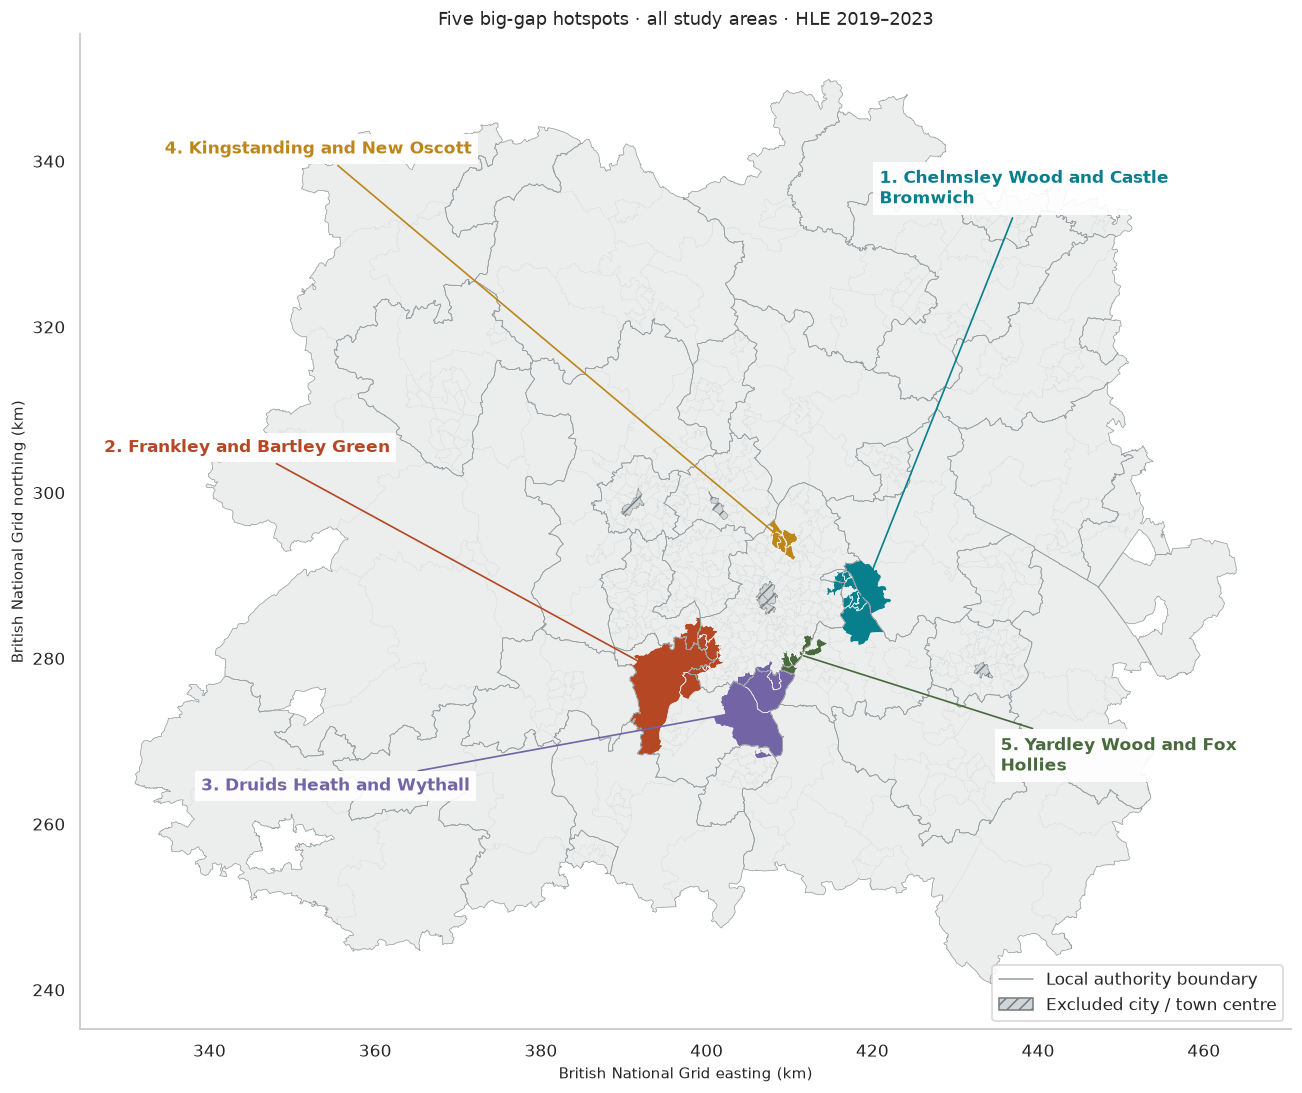

In [14]:
HOTSPOT_COLOURS = {1: "#087f8c", 2: "#b54724", 3: "#7264a5", 4: "#bd861a", 5: "#486a3c"}

# Merge the areas of each authority into one shape, so I can draw council boundaries.
authority_boundaries = map_areas.dissolve(by="authority_code")

fig, ax = plt.subplots(figsize=(12, 11))

# All 660 areas in pale grey, with council boundaries on top.
map_areas.plot(ax=ax, color="#eceeed", edgecolor="#c9cecf", linewidth=0.15)

authority_boundaries.boundary.plot(ax=ax, color="#959b9e", linewidth=0.45)

# Labels sit in fixed spots around the edge (fractions of the axes), joined to their hotspot by a line.
label_positions = {1: (0.66, 0.83), 2: (0.02, 0.58), 3: (0.10, 0.24), 4: (0.07, 0.88), 5: (0.76, 0.26)}

for hotspot_id, codes in hotspot_codes.items():
    selected = map_areas.loc[codes]
    selected.plot(ax=ax, color=HOTSPOT_COLOURS[hotspot_id], edgecolor="white", linewidth=0.45)
    centre = selected.geometry.union_all().centroid
    ax.annotate(f"{hotspot_id}. {textwrap.fill(HOTSPOT_NAMES[hotspot_id], 27)}",
        xy=(centre.x, centre.y), xytext=label_positions[hotspot_id], textcoords="axes fraction",
        fontsize=11, fontweight="bold", color=HOTSPOT_COLOURS[hotspot_id],
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9, "pad": 4},
        arrowprops={"arrowstyle": "-", "color": HOTSPOT_COLOURS[hotspot_id], "lw": 1.1})

# The six visitor hubs are hatched, so it's clear they're excluded rather than missing.
excluded_map = map_areas.loc[map_areas["crime_for_analysis"].isna()]

excluded_map.plot(ax=ax, color="#d1d5d6", edgecolor="#737c80", hatch="///", linewidth=0.3)
ax.set(title="Five big-gap hotspots · all study areas · HLE 2019–2023",
       xlabel="British National Grid easting (km)", ylabel="British National Grid northing (km)")

# The grid is in metres; the axis labels show kilometres.
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1000:.0f}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y / 1000:.0f}"))
ax.set_aspect("equal")
ax.grid(False)
ax.legend(handles=[Line2D([0], [0], color="#959b9e", lw=1, label="Local authority boundary"),
                   Patch(facecolor="#d1d5d6", edgecolor="#737c80", hatch="///",
                         label="Excluded city / town centre")],
          loc="lower right", frameon=True)

fig.tight_layout()

save_figure(fig, "01_hotspot_overview.png")

## 2. What differs between the two sides

I put the higher-HLE area first in each pair. Then I ask whether that side is also better off on each measure: more income, qualifications and employment, or less fuel poverty, nitrogen dioxide (NO₂), recorded crime and anti-social behaviour (ASB).

I scale the differences by each measure's standard deviation across the 654 modelling areas. A standard deviation is one typical step away from the average, so it lets me compare pounds, percentages and pollution on the same scale. Positive differences mean the higher-HLE side is better off. Equal values don't count as better off.

The 50% line on the chart is a coin flip: half of the pairs going each way.

In [15]:
# For each measure, which way counts as better off: more income is better, more crime is worse.
BETTER_DIRECTION = {
    "annual_equivalised_income_after_housing_costs_gbp": 1,
    "level4plus_pct": 1,
    "employed_residents_16plus_pct": 1,
    "fuel_poor_households_pct": -1,
    "no2_area_mean_ug_m3": -1,
    "crime_for_analysis": -1,
    "asb_rows_per_1000_residents": -1}

assert set(BETTER_DIRECTION) == set(features)


# Pairs are stored smaller code first. This turns each pair round so the healthier side comes first.
def higher_first(table):
    higher_a = table["area_a"].map(area_by_code["hle_average"]).gt(table["area_b"].map(area_by_code["hle_average"]))
    ordered = pd.DataFrame({"higher_area_code": np.where(higher_a, table["area_a"], table["area_b"]),
                            "lower_area_code": np.where(higher_a, table["area_b"], table["area_a"])},
                           index=table.index)
    return ordered

In [16]:
# Only pairs where both areas have all seven measures. Three pairs touch a visitor hub.
eligible = big_pairs["area_a"].isin(model_areas["area_code"]) & big_pairs["area_b"].isin(model_areas["area_code"])

eligible_big_pairs = big_pairs.loc[eligible].copy()
assert len(eligible_big_pairs) == 92

ordered_pairs = higher_first(eligible_big_pairs)

within_hotspots = eligible_big_pairs["hotspot_id"].notna()
assert within_hotspots.sum() == len(hotspot_pair_table)

# Each measure's spread across the 654 areas, so differences can be compared in standard steps.
feature_scaler = StandardScaler().fit(model_areas[features])
feature_spread = dict(zip(features, feature_scaler.scale_))

rows = []

for feature in features:
    # Healthier side minus less healthy side, turned so that positive always means better off.
    raw_difference = (ordered_pairs["higher_area_code"].map(area_by_code[feature])
                      - ordered_pairs["lower_area_code"].map(area_by_code[feature]))
    better_difference = BETTER_DIRECTION[feature] * raw_difference
    better = better_difference.gt(0)

    rows.append({"measure": feature, "label": feature_labels[feature],
        "better_direction": "higher" if BETTER_DIRECTION[feature] == 1 else "lower",
        "pair_count": len(ordered_pairs), "better_off_count": int(better.sum()),
        "better_off_share": float(better.mean()),
        "tied_count": int(better_difference.eq(0).sum()),
        "median_better_off_difference_sd": float((better_difference / feature_spread[feature]).median()),
        "predictor_standard_deviation": float(feature_spread[feature]), "predictor_unit": feature_units[feature],
        "hotspot_pair_count": int(within_hotspots.sum()),
        "hotspot_better_off_count": int(better.loc[within_hotspots].sum()),
        "hotspot_better_off_share": float(better.loc[within_hotspots].mean())})

pair_measure_differences = (pd.DataFrame(rows)
                            .sort_values(["better_off_share", "measure"], ascending=[False, True])
                            .reset_index(drop=True))

student_pairs = big_pairs.loc[big_pairs["student_dominated_either"], ["name_a", "name_b"]]

,label,better_off_count,pair_count,Better-off %,Median better-off difference (SD),hotspot_better_off_count,hotspot_pair_count,Hotspot better-off %
0,Household income after housing costs,92,92,100.00,1.98,29,29,100.00
1,Level 4+ qualifications,92,92,100.00,1.45,29,29,100.00
2,Fuel-poor households,84,92,91.30,1.03,26,29,89.66
3,Recorded crime (visitor hubs omitted),82,92,89.13,1.16,22,29,75.86
4,Employed residents aged 16+,78,92,84.78,0.97,28,29,96.55
5,NO₂ area mean,76,92,82.61,0.34,22,29,75.86
6,Anti-social behaviour rate,74,92,80.43,0.75,17,29,58.62


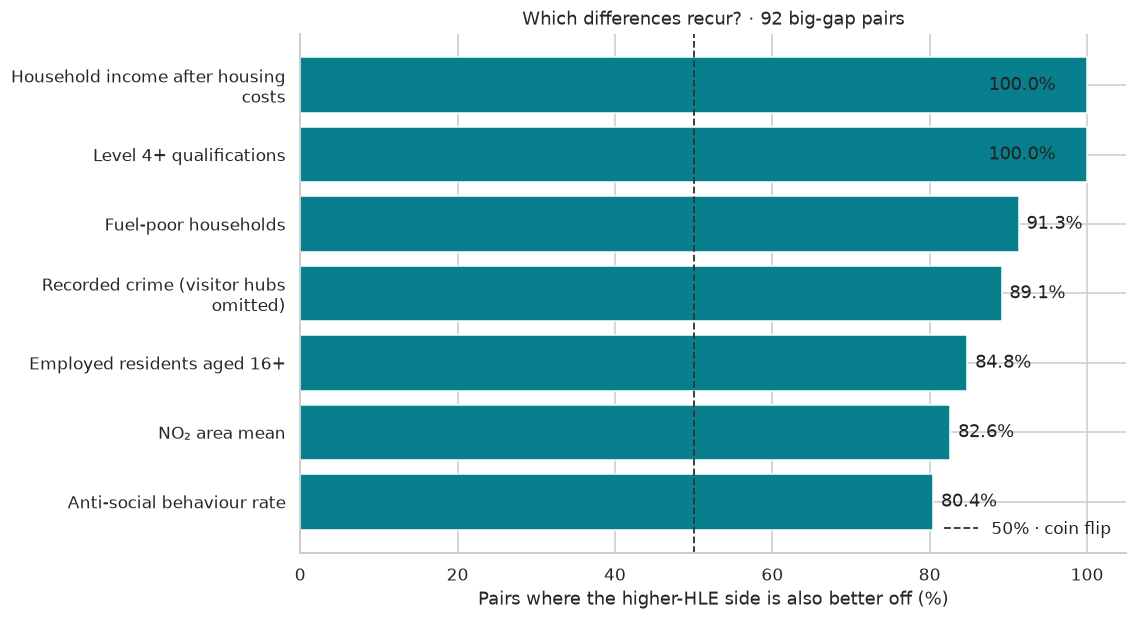

In [17]:
fig, ax = plt.subplots(figsize=(10.5, 5.8))

percentages = 100 * pair_measure_differences["better_off_share"]
positions = np.arange(len(pair_measure_differences))

ax.barh(positions, percentages, color="#087f8c")
ax.set_yticks(positions, [textwrap.fill(label, 34) for label in pair_measure_differences["label"]])
ax.invert_yaxis()

# 50% is what a coin flip would give if the measure had nothing to do with the gap.
ax.axvline(50, color="#333333", linestyle="--", linewidth=1.2, label="50% · coin flip")

for i, value in enumerate(percentages):
    ax.text(min(value + 1, 96), i, f"{value:.1f}%", va="center", ha="left" if value < 95 else "right", color="#222222")

ax.set(xlim=(0, 105), xlabel="Pairs where the higher-HLE side is also better off (%)",
       title=f"Which differences recur? · {len(ordered_pairs)} big-gap pairs", ylabel="")

ax.legend(loc="lower right", frameon=False)

fig.tight_layout()

# Shares shown as percentages, with plainer column names.
display(pair_measure_differences[["label", "better_off_count", "pair_count", "better_off_share",
                                  "median_better_off_difference_sd", "hotspot_better_off_count",
                                  "hotspot_pair_count", "hotspot_better_off_share"]]
        .assign(better_off_share=lambda t: 100 * t["better_off_share"],
                hotspot_better_off_share=lambda t: 100 * t["hotspot_better_off_share"])
        .rename(columns={"better_off_share": "Better-off %",
                         "hotspot_better_off_share": "Hotspot better-off %",
                         "median_better_off_difference_sd": "Median better-off difference (SD)"})
        .round(2))

save_figure(fig, "02_pair_measure_consistency.png")

The first two bars need a health warning. Income and qualifications line up with the healthier side in all 92 pairs, but that was always likely. I picked these pairs because their HLE differs by at least 9.6 years, and income tracks HLE almost exactly across my areas (0.94 in Notebook 03). Neighbours that far apart on HLE were always going to be far apart on income. So the 100% confirms the pattern rather than discovering anything. The size of the difference is still worth knowing: on the healthier side, income is typically about two standard steps higher (1.98) and qualifications about one and a half (1.45).

The bars below 100% say more. Fuel poverty lines up in 91% of pairs, crime in 89%, and anti-social behaviour, the weakest, in 80%. Inside the five hotspots, anti-social behaviour drops to 59%, not far off a coin flip. In these places it barely tells the two sides apart.

Students skew this kind of comparison, because they make income and employment look low. Two big-gap pairs include a student area: Edgbaston South and Selly Oak, and Central Coventry and Earlsdon. The Coventry pair sits out of this comparison anyway, because Central Coventry is one of the excluded centres.

## 3. Inside each local authority

If one authority is simply richer and healthier than its neighbour, that alone could produce a strong link between income and HLE. I take each authority's average off every area's HLE and off each measure. What's left is how far each area sits above or below its own authority's average.

I standardise those seven remaining measures, giving each an average of zero and a standard deviation of one. HLE stays in years, so the new weights can sit beside Notebook 05's weights. A coefficient is the weight given to one measure while the other six are held still. R² is the share of the remaining HLE variation that the fitted model accounts for.

I fit a plain linear regression on all 654 areas, with no cross-validation, because I'm comparing weights here rather than testing prediction on unseen areas.

In [18]:
# Take each authority's average off every area, so only the differences inside each authority are left.
within_values = (model_areas[["hle_average", *features]]
                 - model_areas.groupby("authority_code")[["hle_average", *features]].transform("mean"))
assert np.allclose(within_values.groupby(model_areas["authority_code"]).mean(), 0, atol=1e-10)

# Rescale each measure by its spread within authorities, so the weights are in years per standard step.
within_scaler = StandardScaler()

within_X = within_scaler.fit_transform(within_values[features])

within_y = within_values["hle_average"].to_numpy()

# One fit on all 654 areas. This describes the pattern; it isn't a prediction test.
within_linear = LinearRegression().fit(within_X, within_y)

within_r2 = float(r2_score(within_y, within_linear.predict(within_X)))

within_authority_coefficients = pd.DataFrame({"measure": features,
    "label": [feature_labels[f] for f in features],
    "within_authority_coefficient_years": within_linear.coef_,
    "within_predictor_standard_deviation": within_scaler.scale_,
    "predictor_unit": [feature_units[f] for f in features], "area_count": len(model_areas)})

# Notebook 05's weights go beside them, renamed so the two sets can't be confused.
within_authority_coefficients = within_authority_coefficients.merge(
    coefficients_05[["measure", "standardised_coefficient_years", "predictor_standard_deviation"]].rename(
        columns={"standardised_coefficient_years": "notebook_05_coefficient_years",
                 "predictor_standard_deviation": "notebook_05_predictor_standard_deviation"}),
    on="measure", validate="one_to_one")

within_authority_coefficients = (within_authority_coefficients
                                 .sort_values("notebook_05_coefficient_years", key=abs, ascending=False)
                                 .reset_index(drop=True))

within_authority_coefficients["coefficient_difference_years"] = (
    within_authority_coefficients["within_authority_coefficient_years"]
    - within_authority_coefficients["notebook_05_coefficient_years"])

within_authority_coefficients["within_authority_r2"] = within_r2

,label,notebook_05_coefficient_years,within_authority_coefficient_years,coefficient_difference_years,within_authority_r2
0,Household income after housing costs,3.099,2.414,-0.685,0.866
1,Level 4+ qualifications,1.112,1.112,0.000,0.866
2,NO₂ area mean,-0.614,-0.030,0.584,0.866
3,Recorded crime (visitor hubs omitted),-0.445,-0.336,0.109,0.866
4,Fuel-poor households,-0.304,-0.379,-0.075,0.866
5,Anti-social behaviour rate,-0.203,-0.231,-0.028,0.866
6,Employed residents aged 16+,-0.188,-0.182,0.006,0.866


Within-authority R²: 0.8664


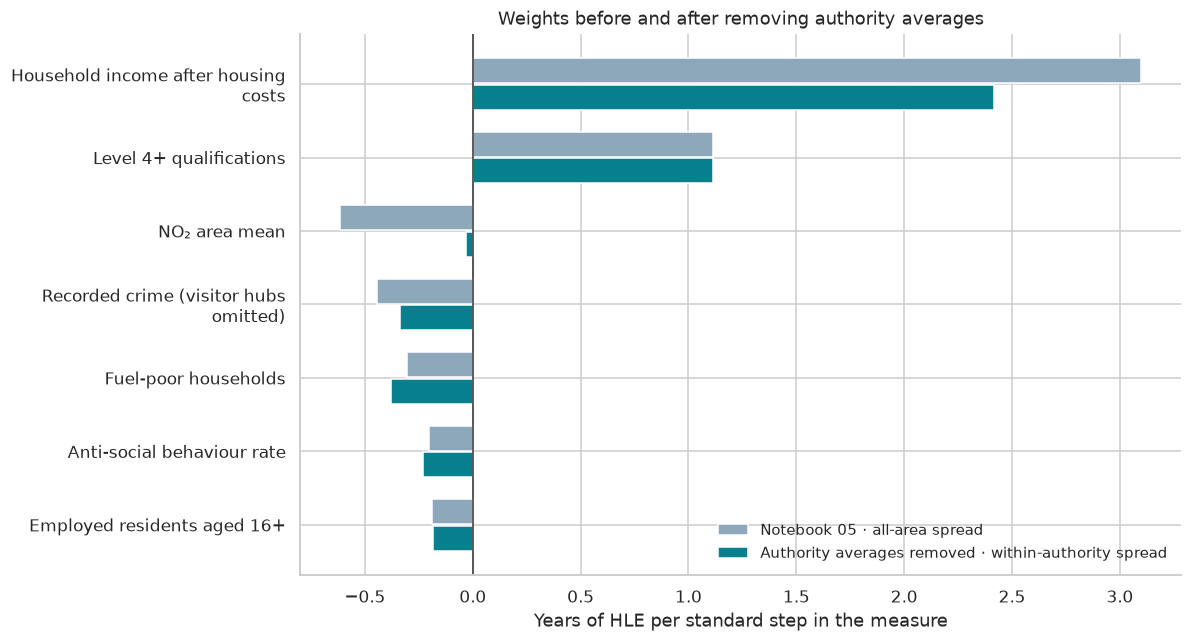

In [19]:
# Two bars per measure: the all-area weight from Notebook 05, and the weight inside authorities.
fig, ax = plt.subplots(figsize=(11, 6))

positions = np.arange(len(features))

ax.barh(positions - 0.18, within_authority_coefficients["notebook_05_coefficient_years"], height=0.34,
        color="#8da8bb", label="Notebook 05 · all-area spread")
ax.barh(positions + 0.18, within_authority_coefficients["within_authority_coefficient_years"], height=0.34,
        color="#087f8c", label="Authority averages removed · within-authority spread")

ax.set_yticks(positions, [textwrap.fill(label, 34) for label in within_authority_coefficients["label"]])
ax.invert_yaxis()
ax.axvline(0, color="#333333", linewidth=1)
ax.set(title="Weights before and after removing authority averages",
       xlabel="Years of HLE per standard step in the measure", ylabel="")

ax.legend(loc="lower right", frameon=False, fontsize=10)

fig.tight_layout()

display(within_authority_coefficients[["label", "notebook_05_coefficient_years",
                                       "within_authority_coefficient_years", "coefficient_difference_years",
                                       "within_authority_r2"]].round(3))
print(f"Within-authority R²: {within_r2:.4f}")

save_figure(fig, "03_within_authority_coefficients.png")

Income still dominates. Its weight is 2.41 years per standard step inside an authority, against 3.10 across the full map. Qualifications come next at 1.11. So the income link isn't just one richer, healthier council sitting next to a poorer one. It runs through the differences inside councils too.

The fitted model accounts for 86.6% of the HLE variation left after the authority averages are removed (R² 0.866). NO₂'s weight falls from -0.61 to -0.03, almost nothing. Its earlier weight mostly travels with differences between authorities.

The standard step has changed as well: income's step is now about £4,085, against £5,034 before. Part of the smaller weight comes from taking a smaller step. I read the comparison as which measures carry most weight in each fit, rather than the effect of one fixed pound amount.

## 4. The five hotspots up close

For each place there's a table of its areas, a flat map and a 3D preview. The maps show the hotspot and, paler, the ring of neighbours around it, so I can see what it sits in. The red lines are the shared boundaries of the big-gap pairs: the edges where HLE drops.

The colours are the dashboard's five HLE bands, from purple (below 55 years) to yellow (70 and over), so the notebook and the dashboard read the same way. The tables carry the six broad ethnic groups to describe each place, not to test anything.

The 3D previews are a first go at the idea behind the web views. Each area is raised by its HLE above a 50-year floor, so the drop at a boundary becomes a step I can see. Each view looks from the low side, so the lower areas sit in front and the higher ones rise behind them. Starting at 50 rather than zero exaggerates the steps on purpose. They're for seeing, not for measuring.

In [20]:
# The ring of neighbours around each hotspot: every area that touches it but isn't part of it.
context_codes = {}

for hotspot_id, codes in hotspot_codes.items():
    membership = set(codes)
    touching = neighbour_pairs.loc[neighbour_pairs["area_a"].isin(membership)
                                   | neighbour_pairs["area_b"].isin(membership)]
    context_codes[hotspot_id] = sorted((set(touching["area_a"]) | set(touching["area_b"])) - membership)

# Short column names for the close-up tables.
display_features = {
    "annual_equivalised_income_after_housing_costs_gbp": "Income (£/year)",
    "level4plus_pct": "Level 4+ (%)", "employed_residents_16plus_pct": "Employed (%)",
    "fuel_poor_households_pct": "Fuel poor (%)", "no2_area_mean_ug_m3": "NO₂ (µg/m³)",
    "crime_for_analysis": "Crime / 1,000", "asb_rows_per_1000_residents": "ASB / 1,000"}

# Each close-up adds a summary here, for the results file at the end.
closeup_summaries = []


# One hotspot's areas, healthiest first, with HLE, prediction, residual and every measure.
def area_table_for_hotspot(hotspot_id):
    selected = (map_areas.loc[hotspot_codes[hotspot_id]]
                .sort_values(["hle_average", "local_area_name"], ascending=[False, True]))
    table = pd.DataFrame({"Area": selected["local_area_name"], "Authority": selected["authority_name"],
        "HLE [95% interval]": selected.apply(
            lambda r: f"{r.hle_average:.2f} [{r.hle_average_lci:.2f}, {r.hle_average_uci:.2f}]", axis=1),
        "Prediction (years)": selected["out_of_fold_prediction"], "Residual (years)": selected["residual"],
        "Group": selected["cluster_label"]})

    for feature in features:
        table[display_features[feature]] = selected[feature]

    table["Student flag"] = selected["student_dominated"]

    for column in ethnicity_columns:
        table[ethnicity_labels[column] + " (%)"] = selected[column]

    table = table.reset_index(drop=True)

    # The summary: lowest and highest areas, the biggest model miss, and the typical actual and predicted gaps.
    lowest, highest = selected.iloc[-1], selected.iloc[0]
    standout_code = selected["residual"].abs().idxmax()
    standout = selected.loc[standout_code]

    pairs_here = hotspot_pair_table.loc[hotspot_pair_table["hotspot_id"].eq(hotspot_id)]
    ordered = higher_first(pairs_here)
    predicted_gap = (ordered["higher_area_code"].map(area_by_code["out_of_fold_prediction"])
                     - ordered["lower_area_code"].map(area_by_code["out_of_fold_prediction"]))
    actual_gap = pairs_here["gap_years"]

    closeup_summaries.append({"hotspot_id": hotspot_id,
        "lowest_name": str(lowest.local_area_name), "lowest_hle": float(lowest.hle_average),
        "highest_name": str(highest.local_area_name), "highest_hle": float(highest.hle_average),
        "standout_name": str(standout.local_area_name), "standout_hle": float(standout.hle_average),
        "standout_prediction": float(standout.out_of_fold_prediction),
        "standout_residual": float(standout.residual),
        "median_actual_gap_years": float(actual_gap.median()),
        "median_predicted_gap_years": float(predicted_gap.median()),
        "student_flag_count": int(selected["student_dominated"].sum()),
        "context_area_count": len(context_codes[hotspot_id])})

    # Horizontal scrolling keeps the full place table readable without shrinking the text.
    table_html = table.round(1).to_html(index=False, border=0, classes="hotspot-table", na_rep="Not available")
    style = ("<style>.hotspot-table th,.hotspot-table td{min-width:100px;padding:7px;text-align:left;"
             "white-space:normal}.hotspot-table{font-size:13px}.hotspot-table th{vertical-align:bottom}</style>")
    return HTML(style + '<div style="max-width:100%;overflow-x:auto">' + table_html + '</div>')

In [21]:
# The five HLE colour bands as legend entries, shared by the flat and 3D maps.
def band_legend():
    return [Patch(facecolor=colour, edgecolor="#888888", label=label)
            for colour, label in zip(HLE_COLOURS, HLE_BAND_LABELS)]


# Small areas need moved labels and leaders so their names don't hide one another.
# The offsets are in metres, east and north of the label's natural spot.
LABEL_OFFSETS_METRES = {
    "Castle Bromwich East": (-2500, 600), "Smith's Wood North": (-500, 2500),
    "Smith's Wood South": (2500, 1500), "Shard End": (-1800, 0),
    "Fordbridge": (-2000, -1200), "Chelmsley Wood West": (-1800, -4200),
    "Chelmsley Wood East": (3300, -1400), "Halesowen East": (-2400, 800),
    "Woodgate Valley": (1400, 1400), "Woodgate": (-2300, 0), "Yardley Wood West": (-1300, 450),
    "Yardley Wood East": (900, -500)}


# A flat map of one hotspot: its areas in HLE colours, the ring of neighbours paler behind,
# and the shared edges of its big-gap pairs drawn in red.
def flat_map(hotspot_id):
    selected = map_areas.loc[hotspot_codes[hotspot_id]]
    context = map_areas.loc[context_codes[hotspot_id]]

    fig, ax = plt.subplots(figsize=(11, 9.5))
    context.plot(ax=ax, color=context["hle_colour"], alpha=0.30, edgecolor="#879196", linewidth=0.5)
    selected.plot(ax=ax, color=selected["hle_colour"], edgecolor="white", linewidth=1.6)

    # Any excluded centre in view gets the same hatching as on the overview map.
    shown = map_areas.loc[hotspot_codes[hotspot_id] + context_codes[hotspot_id]]
    excluded_here = shown.loc[shown["crime_for_analysis"].isna()]
    if not excluded_here.empty:
        excluded_here.plot(ax=ax, color="#d1d5d6", edgecolor="#737c80", hatch="///", linewidth=0.6)

    # Where two areas' outlines overlap is the boundary they share: that's the line the big gap crosses.
    shared_edges = []
    for pair in hotspot_pair_table.loc[hotspot_pair_table["hotspot_id"].eq(hotspot_id)].itertuples():
        shared = map_areas.loc[pair.area_a, "geometry"].boundary.intersection(
            map_areas.loc[pair.area_b, "geometry"].boundary)
        assert shared.length > 1, f"No shared edge for {pair.area_a}, {pair.area_b}"
        shared_edges.append(shared)
    gpd.GeoSeries(shared_edges, crs=27700).plot(ax=ax, color="#e04532", linewidth=2.0, zorder=4)

    # Names sit inside their areas, or on a short leader line where they've been moved.
    for _, row in selected.iterrows():
        point = row.geometry.representative_point()
        dx, dy = LABEL_OFFSETS_METRES.get(row.local_area_name, (0, 0))
        ax.annotate(textwrap.fill(row.local_area_name, 12), xy=(point.x, point.y), xytext=(point.x + dx, point.y + dy),
                fontsize=9.5, ha="center", va="center",
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.92, "pad": 2},
                arrowprops={"arrowstyle": "-", "color": "#46565d", "lw": 0.8} if dx or dy else None, zorder=5)

    # Frame the hotspot and its neighbours, with a small margin.
    west, south, east, north = shown.total_bounds
    margin = 0.04 * max(east - west, north - south)
    ax.set(xlim=(west - margin, east + margin), ylim=(south - margin, north + margin),
        title=f"{hotspot_id}. {HOTSPOT_NAMES[hotspot_id]}\nAverage HLE · 2019–2023 · one ring of neighbours",
        xlabel="British National Grid easting (km)", ylabel="British National Grid northing (km)")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1000:.1f}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y / 1000:.1f}"))
    ax.set_aspect("equal")
    ax.grid(False)

    handles = band_legend() + [Line2D([0], [0], color="#e04532", lw=2.0, label="Big-gap shared edge")]
    if not excluded_here.empty:
        handles.append(Patch(facecolor="#d1d5d6", edgecolor="#737c80", hatch="///", label="Excluded centre"))
    ax.legend(handles=handles, title="Average HLE (years)", loc="upper center", bbox_to_anchor=(0.5, -0.09),
              ncol=3, frameon=False, fontsize=10)
    fig.tight_layout()

    save_figure(fig, f"hotspot_{hotspot_id}_flat_map.png")

In [22]:
# Clipping can leave a mix of shapes, so I keep only the polygon pieces.
def polygon_parts(geometry):
    if geometry.is_empty:
        return []
    if geometry.geom_type == "Polygon":
        return [geometry]
    if hasattr(geometry, "geoms"):
        return [part for piece in geometry.geoms for part in polygon_parts(piece)]
    return []


# Turn one flat area into a solid block: a roof at the given height, plus a wall along every edge.
# Triangles close concave roofs and holes without filling empty space inside the area.
# Coordinates become kilometres from the view's centre.
def block_faces(polygon, origin_x, origin_y, height):
    faces = []
    top_faces = []

    for triangle in shapely.constrained_delaunay_triangles(polygon).geoms:
        vertices = [((x - origin_x) / 1000, (y - origin_y) / 1000, height)
                    for x, y in list(triangle.exterior.coords)[:-1]]
        top_faces.append(vertices)

    # Each wall runs from one corner of the outline to the next, from the ground up to the roof.
    for ring in [polygon.exterior, *polygon.interiors]:
        coordinates = list(ring.coords)
        for (x1, y1), (x2, y2) in zip(coordinates[:-1], coordinates[1:]):
            a, b = ((x1 - origin_x) / 1000, (y1 - origin_y) / 1000), ((x2 - origin_x) / 1000, (y2 - origin_y) / 1000)
            faces.append([(a[0], a[1], 0), (b[0], b[1], 0), (b[0], b[1], height), (a[0], a[1], height)])

    return top_faces, faces


# Frame each view on the hotspot itself, with a margin, so the blocks fill the picture.
preview_spans_km = {h: 1.35 * max(map_areas.loc[hotspot_codes[h]].total_bounds[2:]
                                  - map_areas.loc[hotspot_codes[h]].total_bounds[:2]) / 1000
                    for h in HOTSPOT_NAMES}

# Every view shares one height scale, so the five can be compared.
preview_max_height = float(np.ceil(map_areas["hle_average"].max() - HLE_FLOOR))


def preview_3d(hotspot_id):
    selected = map_areas.loc[hotspot_codes[hotspot_id]].copy()
    context = map_areas.loc[context_codes[hotspot_id]].copy()
    bounds = map_areas.loc[hotspot_codes[hotspot_id]].total_bounds
    origin_x, origin_y = (bounds[0] + bounds[2]) / 2, (bounds[1] + bounds[3]) / 2

    # Context outside the frame would spill past the 3D box, so I clip it to the frame.
    half_metres = preview_spans_km[hotspot_id] * 1000 / 2
    view_box = (origin_x - half_metres, origin_y - half_metres, origin_x + half_metres, origin_y + half_metres)

    fig = plt.figure(figsize=(11, 8.5))
    ax = fig.add_subplot(111, projection="3d")

    # The bounds are set explicitly below; flat context doesn't need automatic 3D limits.
    ax.set_autoscale_on(False)

    # Neighbours lie flat and grey, as a floor plan around the blocks.
    for _, row in context.iterrows():
        geometry = shapely.clip_by_rect(row.geometry.simplify(20, preserve_topology=True), *view_box)
        for polygon in polygon_parts(geometry):
            tops, _ = block_faces(polygon, origin_x, origin_y, 0)
            ax.add_collection3d(Poly3DCollection(tops, facecolors="#e3e7e7", edgecolors="none"))

    # Hotspot areas rise to their HLE above the floor. Walls are a darker shade of the roof colour.
    solid_faces = []
    solid_colours = []

    for _, row in selected.iterrows():
        height = float(row.hle_average - HLE_FLOOR)
        assert height > 0
        geometry = row.geometry.simplify(20, preserve_topology=True)
        for polygon in polygon_parts(geometry):
            tops, sides = block_faces(polygon, origin_x, origin_y, height)
            side_colour = tuple(0.73 * channel for channel in to_rgb(row.hle_colour))
            bottom = [[(x, y, 0) for x, y, _ in face] for face in tops]
            solid_faces.extend(tops + sides + bottom)
            solid_colours.extend([row.hle_colour] * len(tops) + [side_colour] * (len(sides) + len(bottom)))

    # Sort all faces together so a whole tall block can't wrongly hide a nearer low roof.
    ax.add_collection3d(Poly3DCollection(solid_faces, facecolors=solid_colours, edgecolors="none",
                                         linewidths=0, antialiased=False))

    half = preview_spans_km[hotspot_id] / 2
    ax.set(xlim=(-half, half), ylim=(-half, half), zlim=(0, preview_max_height),
           xlabel="East from view centre (km)", ylabel="North from view centre (km)", zlabel="HLE minus 50 (years)")

    # Put the camera on the lower-HLE side, weighting each area by how far it sits below the patch's highest.
    points = selected.geometry.representative_point()
    weights = (selected["hle_average"].max() - selected["hle_average"]).to_numpy()
    low_x = np.average(points.x.to_numpy() - origin_x, weights=weights)
    low_y = np.average(points.y.to_numpy() - origin_y, weights=weights)
    azimuth = float(np.degrees(np.arctan2(low_y, low_x)))
    ax.view_init(elev=VIEW_ELEVATION, azim=azimuth)

    ax.set_box_aspect((1, 1, 0.45))
    ax.set_zticks([0, 10, 20])
    ax.set_title(f"{hotspot_id}. {HOTSPOT_NAMES[hotspot_id]}\nAverage HLE · 2019–2023 · 50-year floor", pad=22)
    ax.legend(handles=band_legend(), title="Average HLE (years)", loc="upper left", bbox_to_anchor=(-0.04, 0.95),
              frameon=False, fontsize=10)
    fig.text(0.5, 0.04, "The height is for seeing the drop, not for measuring it.", ha="center", fontsize=11)
    fig.subplots_adjust(left=0.02, right=0.92, bottom=0.13, top=0.89)

    save_figure(fig, f"hotspot_{hotspot_id}_3d_preview.png")

### 1. Chelmsley Wood and Castle Bromwich

This is the patch I keep coming back to. Castle Bromwich East has HLE of 69.55 years against a prediction of 64.74, leaving 4.81 years above what its measures suggest. Across the patch's pairs the median actual gap is 10.50 years, while the median predicted gap is 6.21. The measures see a divide here, but they miss a sizeable part of it. The map puts Castle Bromwich East beside the lower-HLE Smith's Wood areas, with Chelmsley Wood further south.

In [23]:
display(area_table_for_hotspot(1))

Area,Authority,HLE [95% interval],Prediction (years),Residual (years),Group,Income (£/year),Level 4+ (%),"Crime / 1,000",Fuel poor (%),NO₂ (µg/m³),Employed (%),"ASB / 1,000",Student flag,White British (%),Other White (%),Asian (%),Black (%),Mixed (%),Other (%)
Castle Bromwich East,Solihull,"69.55 [68.40, 70.70]",64.7,4.8,Fewer qualifications / Lower income,35311,23.5,129.7,9.0,14.4,57.4,6.5,False,85.2,2.1,7.6,1.5,3.0,0.7
Coleshill,North Warwickshire,"67.75 [66.94, 68.56]",66.2,1.6,Fewer qualifications / Lower income,36040,27.2,68.2,9.1,13.3,59.7,13.2,False,92.4,2.8,1.3,0.5,2.7,0.3
Marston Green,Solihull,"65.40 [64.29, 66.51]",61.9,3.5,Higher ASB / Higher recorded crime,33577,25.9,271.8,8.6,14.0,56.5,14.5,False,83.4,2.9,5.1,2.9,4.5,1.3
Smith's Wood South,Solihull,"58.10 [56.95, 59.25]",59.8,-1.7,Fewer qualifications / Lower income,27640,17.2,92.4,10.8,14.0,52.6,7.9,False,81.7,4.0,3.5,4.5,5.4,1.0
Shard End,Birmingham,"57.85 [56.84, 58.86]",59.5,-1.6,Fewer qualifications / Lower income,26808,17.8,98.6,10.6,13.6,51.8,6.2,False,74.8,4.4,5.9,6.5,7.3,1.1
Chelmsley Wood West,Solihull,"57.40 [56.34, 58.46]",55.9,1.5,Higher ASB / Higher recorded crime,24515,16.5,212.4,11.7,13.0,49.4,27.5,False,84.3,3.6,2.7,3.3,5.4,0.6
Smith's Wood North,Solihull,"57.25 [56.15, 58.35]",58.5,-1.3,Fewer qualifications / Lower income,25745,16.6,88.2,12.4,14.6,51.4,4.8,False,83.3,2.6,1.8,5.3,6.2,0.8
Fordbridge,Solihull,"55.70 [54.57, 56.83]",58.7,-3.0,Fewer qualifications / Lower income,26291,17.2,118.5,13.1,12.9,51.7,8.1,False,82.4,3.8,3.1,3.4,6.6,0.7
Chelmsley Wood East,Solihull,"55.55 [54.70, 56.40]",58.7,-3.1,More fuel poverty / Less employment,26486,16.9,121.2,12.6,13.6,50.2,9.4,False,85.1,3.8,2.1,3.1,5.6,0.3


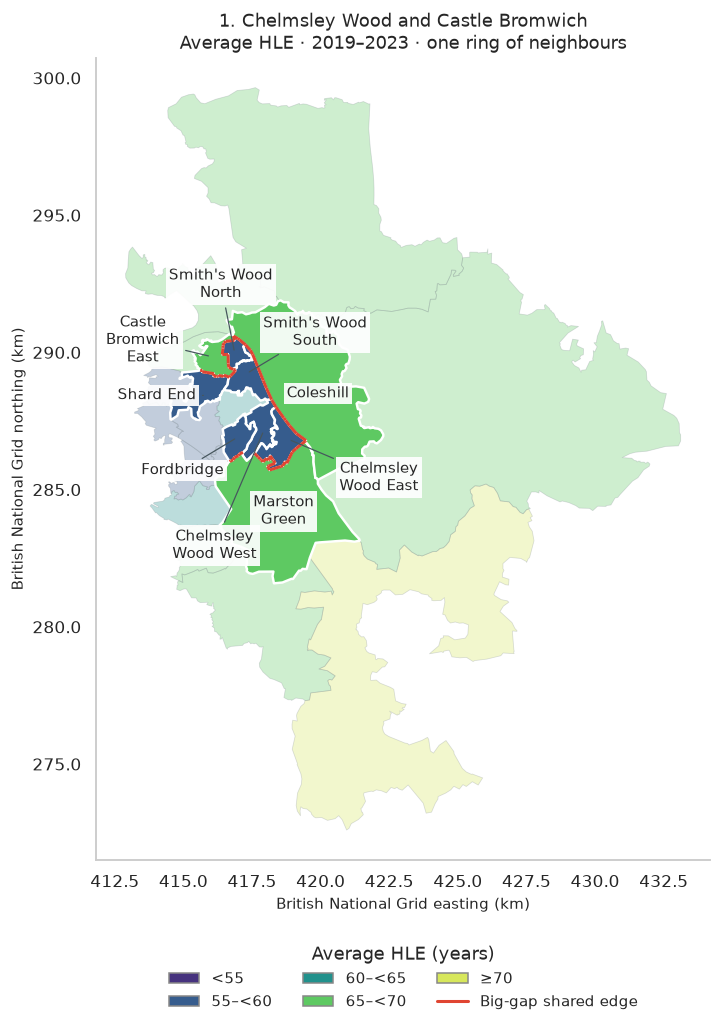

In [24]:
flat_map(1)

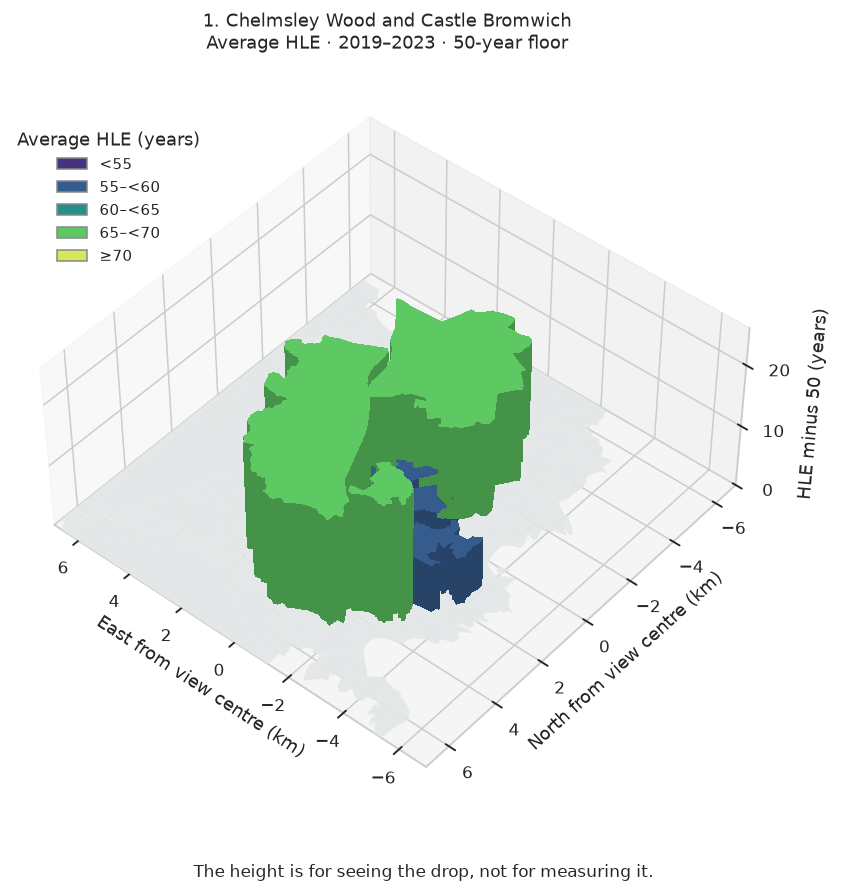

In [25]:
preview_3d(1)

### 2. Frankley and Bartley Green

Every big-gap pair here crosses an authority boundary. The higher-HLE areas of Dodford, Rubery West and Halesowen East sit right beside the lower-HLE Birmingham areas. Frankley stands out most: 55.80 years against a prediction of 59.61, so 3.81 years below what its measures suggest. The measures pick up much of the divide, but not all of it. The median actual gap is 12.10 years; the model expected 9.32.

In [26]:
display(area_table_for_hotspot(2))

Area,Authority,HLE [95% interval],Prediction (years),Residual (years),Group,Income (£/year),Level 4+ (%),"Crime / 1,000",Fuel poor (%),NO₂ (µg/m³),Employed (%),"ASB / 1,000",Student flag,White British (%),Other White (%),Asian (%),Black (%),Mixed (%),Other (%)
Dodford,Bromsgrove,"70.95 [69.99, 71.91]",70.4,0.6,Higher income / More qualifications,38356,38.5,54.2,13.1,7.3,57.1,8.4,False,93.1,2.1,1.9,0.4,2.0,0.5
Halesowen East,Dudley,"70.60 [69.50, 71.70]",69.7,0.9,Higher income / More qualifications,38036,33.5,31.6,8.2,11.1,54.1,2.8,False,82.1,1.8,9.4,2.0,2.7,2.0
Rubery West,Bromsgrove,"67.60 [66.49, 68.71]",66.7,0.9,Higher income / More qualifications,34636,27.4,51.6,9.4,8.7,57.2,10.4,False,92.3,2.6,1.5,1.1,2.3,0.3
Woodgate,Birmingham,"59.95 [58.82, 61.08]",60.7,-0.7,Fewer qualifications / Lower income,26984,22.1,101.9,11.0,11.1,49.3,7.5,False,72.5,3.2,5.0,10.3,7.1,1.9
Woodgate Valley,Birmingham,"58.50 [57.37, 59.63]",60.7,-2.2,Fewer qualifications / Lower income,26761,24.7,107.4,11.8,11.7,48.3,8.2,False,63.4,4.5,9.9,12.2,6.5,3.5
Bartley Green,Birmingham,"58.20 [57.17, 59.23]",61.1,-2.9,Fewer qualifications / Lower income,26879,26.4,124.6,11.4,10.0,50.5,10.9,False,66.9,4.5,8.5,10.1,7.5,2.6
Allens Cross,Birmingham,"57.60 [56.57, 58.63]",60.5,-2.9,Fewer qualifications / Lower income,27439,22.8,95.5,15.5,10.3,52.8,9.8,False,70.4,5.2,6.8,7.9,6.9,2.8
Frankley,Birmingham,"55.80 [54.83, 56.77]",59.6,-3.8,Fewer qualifications / Lower income,25556,20.1,120.9,11.2,9.4,47.9,11.1,False,74.2,3.5,3.8,9.4,7.4,1.8


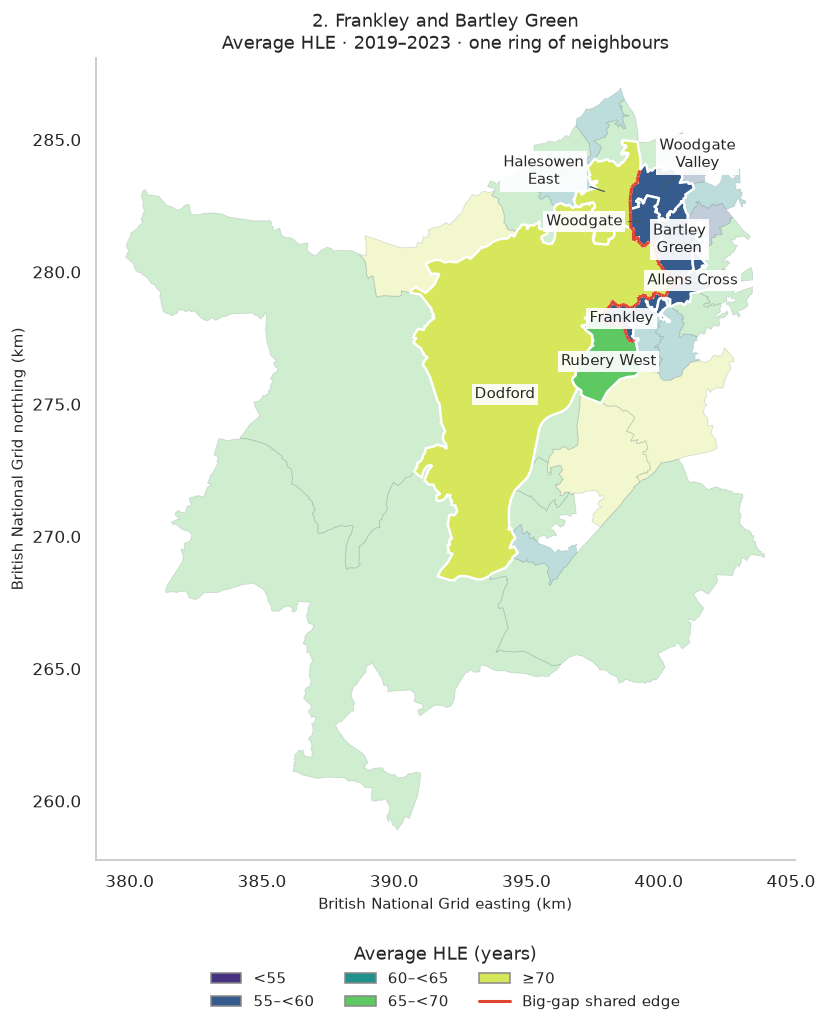

In [27]:
flat_map(2)

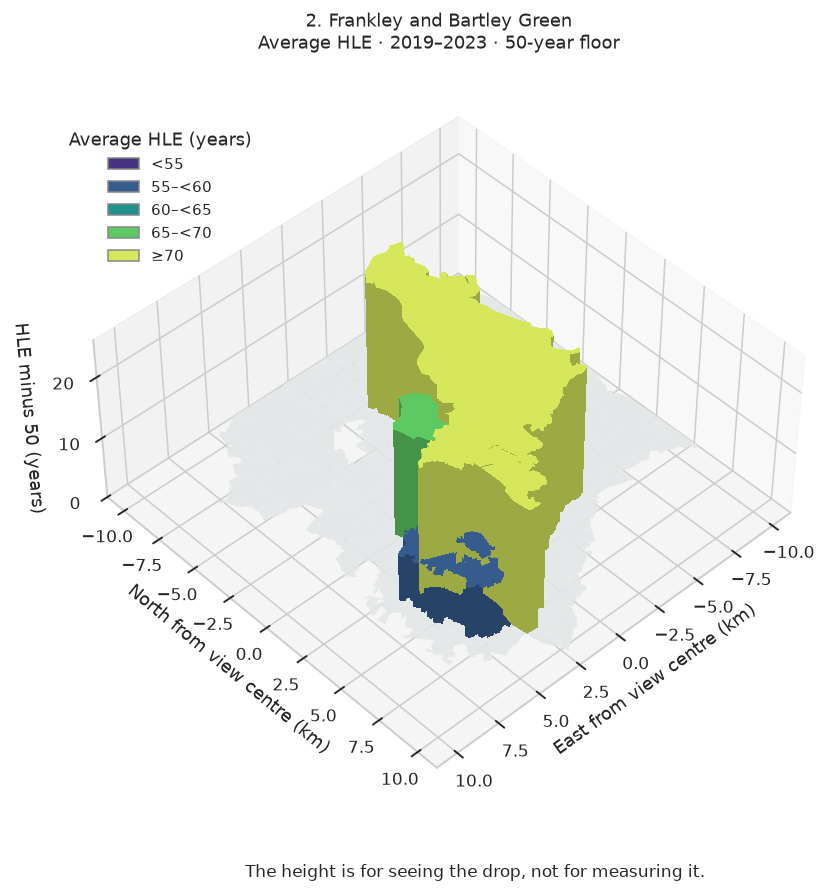

In [28]:
preview_3d(2)

### 3. Druids Heath and Wythall

The darkest area is Druids Heath, at 54.20 years, while Alvechurch reaches 71.10. Those are the two ends of the whole patch, not a single pair. Druids Heath is 3.77 years below its prediction of 57.97. Every big-gap pair here crosses an authority boundary, including the southern edge where Church Hill South meets Alvechurch. The drops repeat along more than one boundary, and Druids Heath is the place I'd look at first.

In [29]:
display(area_table_for_hotspot(3))

Area,Authority,HLE [95% interval],Prediction (years),Residual (years),Group,Income (£/year),Level 4+ (%),"Crime / 1,000",Fuel poor (%),NO₂ (µg/m³),Employed (%),"ASB / 1,000",Student flag,White British (%),Other White (%),Asian (%),Black (%),Mixed (%),Other (%)
Alvechurch,Bromsgrove,"71.10 [70.12, 72.08]",70.4,0.7,Higher income / More qualifications,38433,39.6,63.6,10.3,8.0,56.3,10.4,False,90.9,3.0,2.7,0.5,2.6,0.3
Hollywood,Bromsgrove,"69.75 [68.25, 71.25]",68.3,1.4,Higher income / More qualifications,36186,30.8,40.6,7.9,9.3,53.5,8.3,False,88.6,3.6,2.7,0.8,3.5,0.8
Wythall,Bromsgrove,"69.35 [68.31, 70.39]",70.1,-0.8,Higher income / More qualifications,38685,33.9,51.0,7.8,8.8,54.9,10.9,False,88.6,3.0,4.3,1.0,2.4,0.7
Church Hill South,Redditch,"59.65 [58.34, 60.96]",60.4,-0.8,Fewer qualifications / Lower income,27554,18.1,71.2,11.8,8.5,60.3,13.0,False,80.7,12.1,1.7,1.2,3.6,0.6
Hawkesley,Birmingham,"56.40 [55.37, 57.43]",59.4,-3.0,More fuel poverty / Less employment,25145,22.0,126.9,12.0,10.4,46.6,9.9,False,69.8,3.7,5.9,10.0,7.6,3.0
Druids Heath,Birmingham,"54.20 [53.05, 55.35]",58.0,-3.8,More fuel poverty / Less employment,23709,18.0,117.4,13.1,10.7,43.0,10.1,False,64.5,4.2,8.7,11.7,6.9,3.9


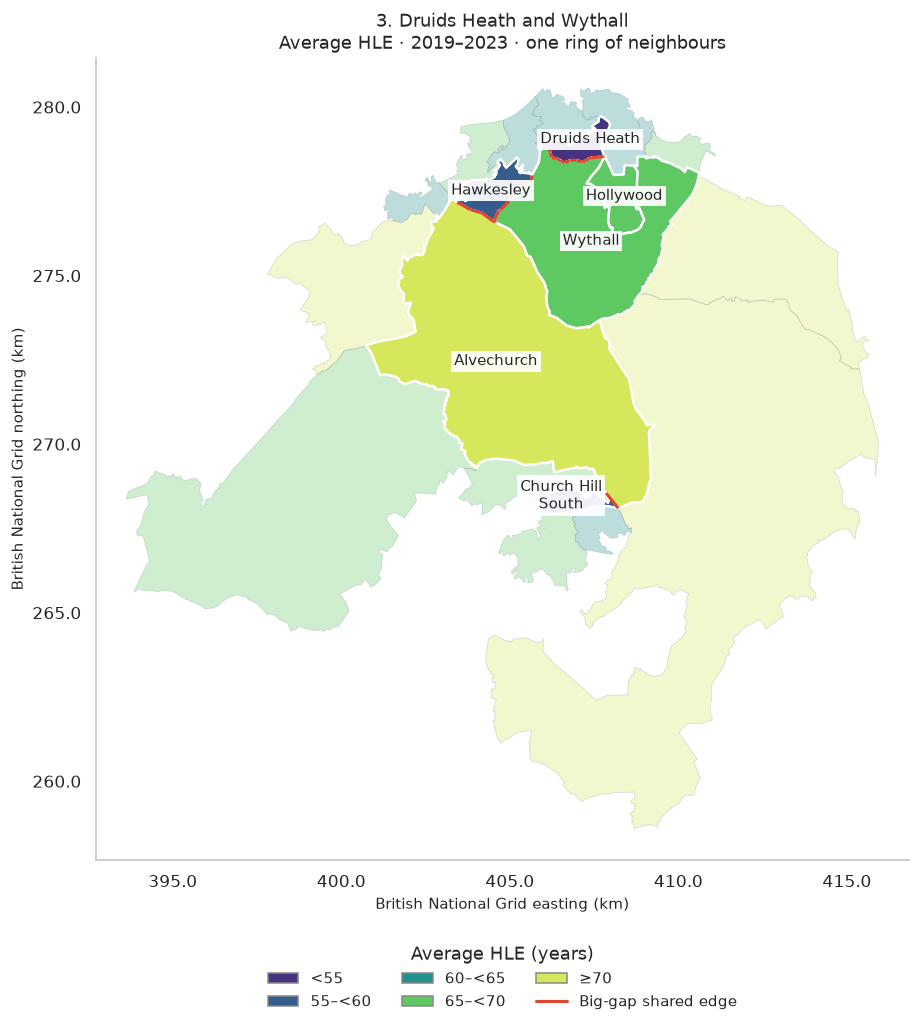

In [30]:
flat_map(3)

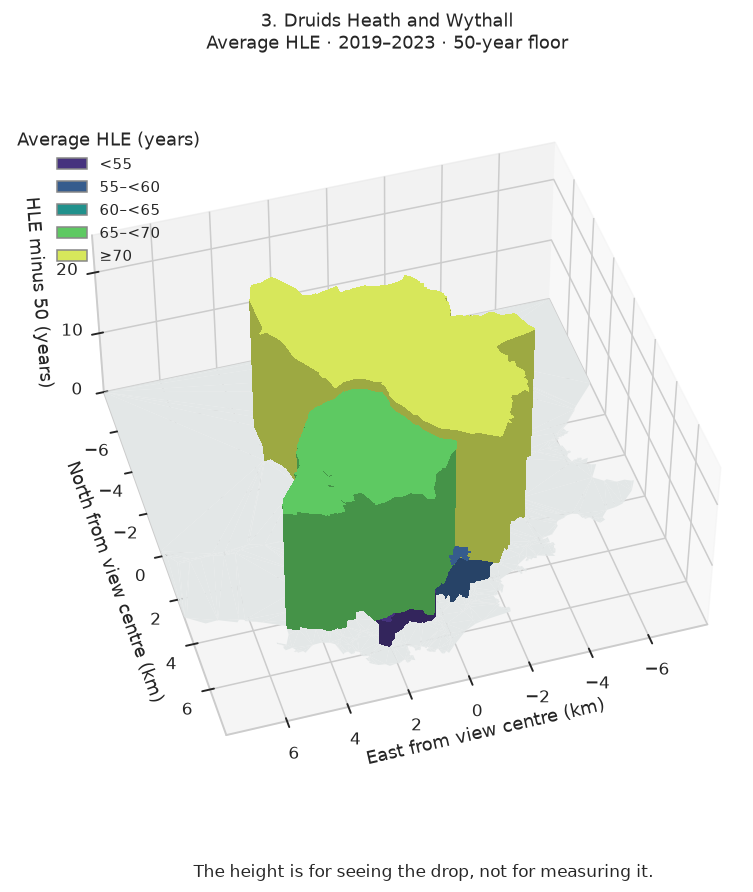

In [31]:
preview_3d(3)

### 4. Kingstanding and New Oscott

This one stays entirely inside Birmingham, so a difference between councils can't be the whole story. New Oscott and Perry Common College Road share the largest selected neighbour gap, 15.85 years. Perry Common College Road has HLE of 54.60 against a prediction of 58.32, leaving 3.72 years below expected. The other big-gap edges connect the same local divide through Kingstanding and Short Heath. It's the clearest reminder that averages for a whole authority can hide a sharp drop inside it.

In [32]:
display(area_table_for_hotspot(4))

Area,Authority,HLE [95% interval],Prediction (years),Residual (years),Group,Income (£/year),Level 4+ (%),"Crime / 1,000",Fuel poor (%),NO₂ (µg/m³),Employed (%),"ASB / 1,000",Student flag,White British (%),Other White (%),Asian (%),Black (%),Mixed (%),Other (%)
New Oscott,Birmingham,"70.45 [69.51, 71.39]",69.3,1.1,Higher income / More qualifications,37634,41.7,99.6,8.7,13.8,56.6,9.0,False,69.4,5.4,14.9,4.5,3.6,2.2
Kingstanding North,Birmingham,"69.15 [68.01, 70.29]",66.5,2.7,Higher income / More qualifications,34826,32.2,61.3,10.1,13.2,59.0,6.4,False,72.0,3.4,14.0,4.5,4.2,1.9
Short Heath,Birmingham,"57.90 [56.98, 58.82]",59.8,-1.9,Fewer qualifications / Lower income,27084,24.1,94.8,14.4,15.1,53.5,6.3,False,54.3,9.7,14.1,12.4,6.5,3.0
Kingstanding South East,Birmingham,"55.30 [54.42, 56.18]",57.3,-2.0,More fuel poverty / Less employment,24864,18.5,130.4,15.6,14.5,50.2,13.3,False,65.3,6.7,10.3,11.2,4.7,1.8
Perry Common College Road,Birmingham,"54.60 [53.75, 55.45]",58.3,-3.7,More fuel poverty / Less employment,24824,21.5,98.7,12.5,14.6,48.0,12.5,False,57.6,6.7,12.2,14.8,6.7,2.0


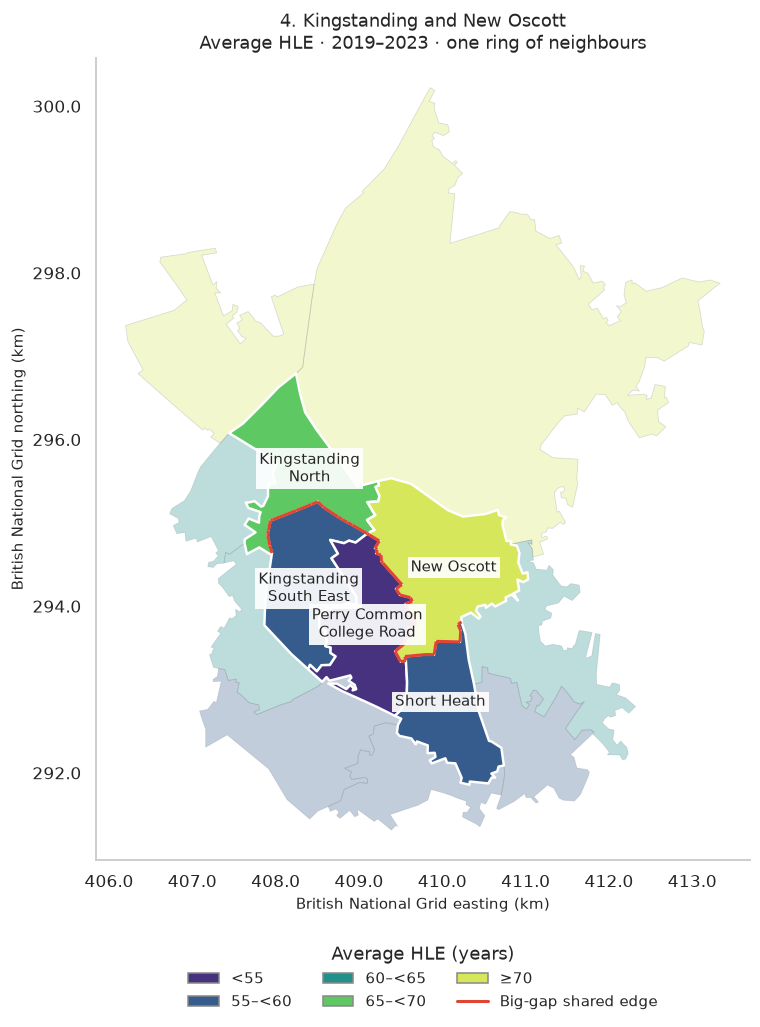

In [33]:
flat_map(4)

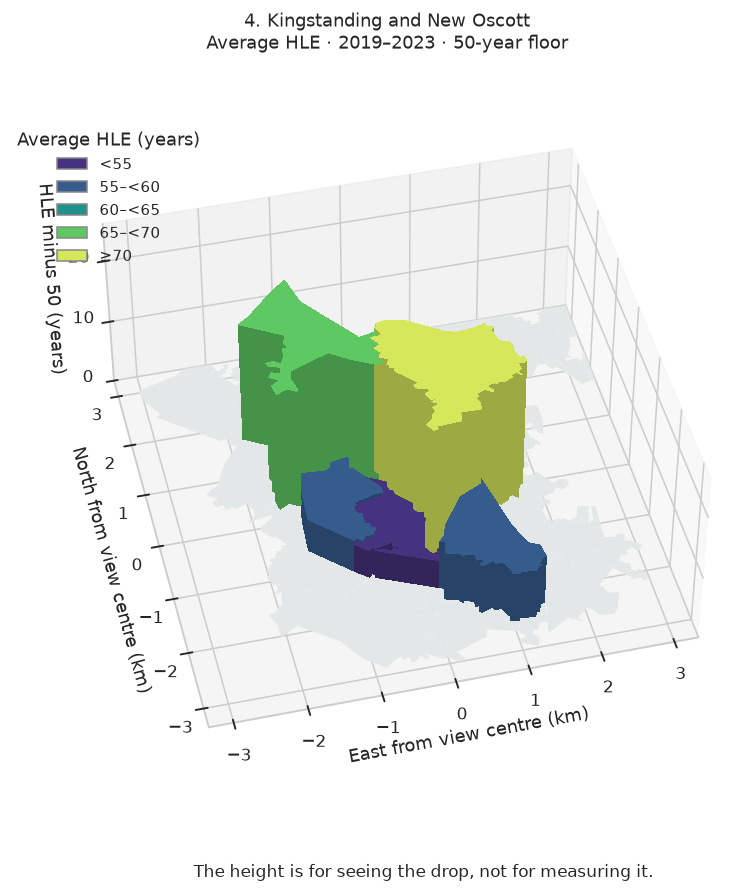

In [34]:
preview_3d(4)

### 5. Yardley Wood and Fox Hollies

Ulverley Green reaches 72.00 years, beside Fox Hollies at 56.35: their pair is 15.65 years apart. Only half of this patch's big-gap pairs cross between Birmingham and Solihull. The others run inside Birmingham, around Yardley Wood. Yardley Wood West has the patch's biggest residual, 3.61 years below its prediction. So this patch has both kinds of boundary, between councils and inside one.

In [35]:
display(area_table_for_hotspot(5))

Area,Authority,HLE [95% interval],Prediction (years),Residual (years),Group,Income (£/year),Level 4+ (%),"Crime / 1,000",Fuel poor (%),NO₂ (µg/m³),Employed (%),"ASB / 1,000",Student flag,White British (%),Other White (%),Asian (%),Black (%),Mixed (%),Other (%)
Ulverley Green,Solihull,"72.00 [70.83, 73.17]",71.6,0.4,Higher income / More qualifications,38586,46.6,25.1,7.1,11.9,54.4,0.5,False,71.1,5.4,17.9,0.9,2.7,1.9
Yardley Wood East,Birmingham,"67.05 [66.02, 68.08]",68.0,-0.9,Higher income / More qualifications,35553,36.1,49.3,11.2,11.5,57.8,1.3,False,48.6,6.9,35.7,2.0,3.8,3.1
Solihull Lodge,Solihull,"66.95 [65.82, 68.07]",66.5,0.5,Higher income / More qualifications,34412,29.6,67.9,9.3,10.4,56.1,3.8,False,81.1,3.3,9.4,1.9,3.0,1.3
Yardley Wood West,Birmingham,"56.80 [55.69, 57.91]",60.4,-3.6,Fewer qualifications / Lower income,26615,24.9,95.6,14.0,11.3,49.2,10.1,False,56.4,5.1,23.2,5.4,5.1,4.9
Fox Hollies,Birmingham,"56.35 [55.47, 57.23]",59.0,-2.7,More fuel poverty / Less employment,25614,22.2,87.6,16.0,12.5,52.2,6.8,False,44.3,6.5,33.9,5.4,6.2,3.7


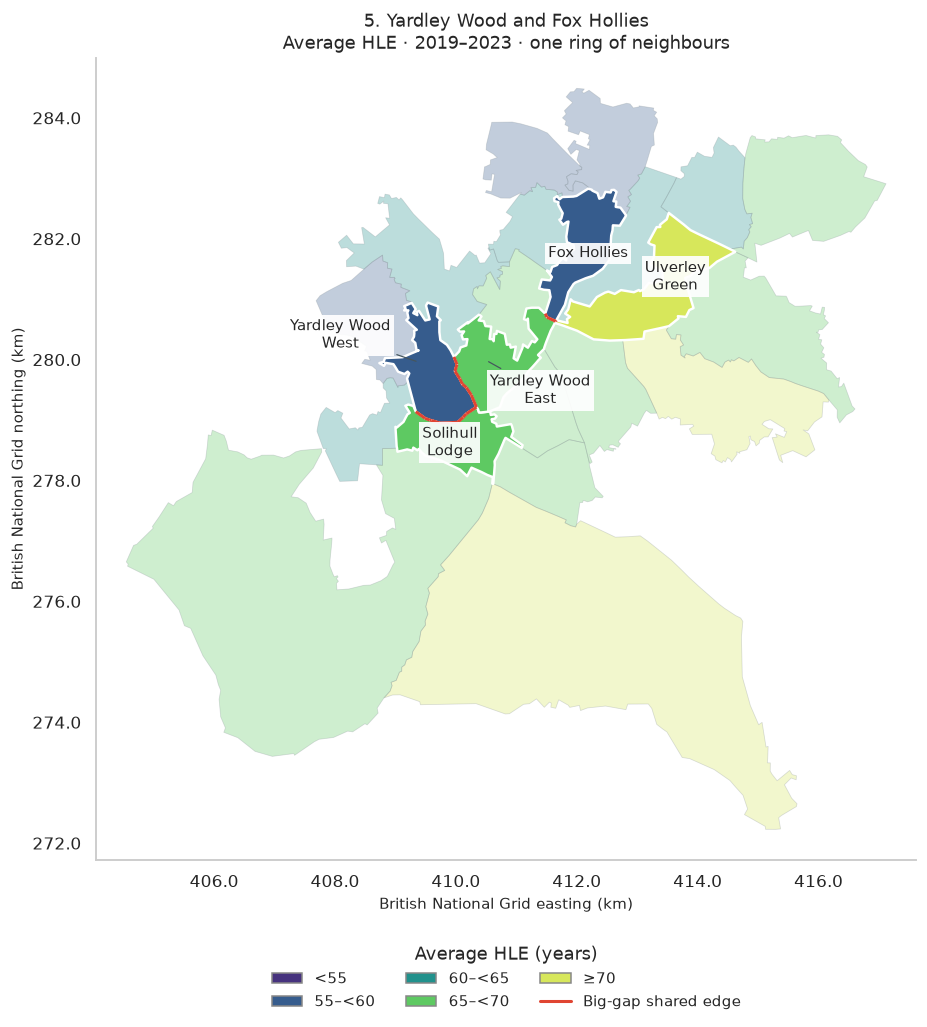

In [36]:
flat_map(5)

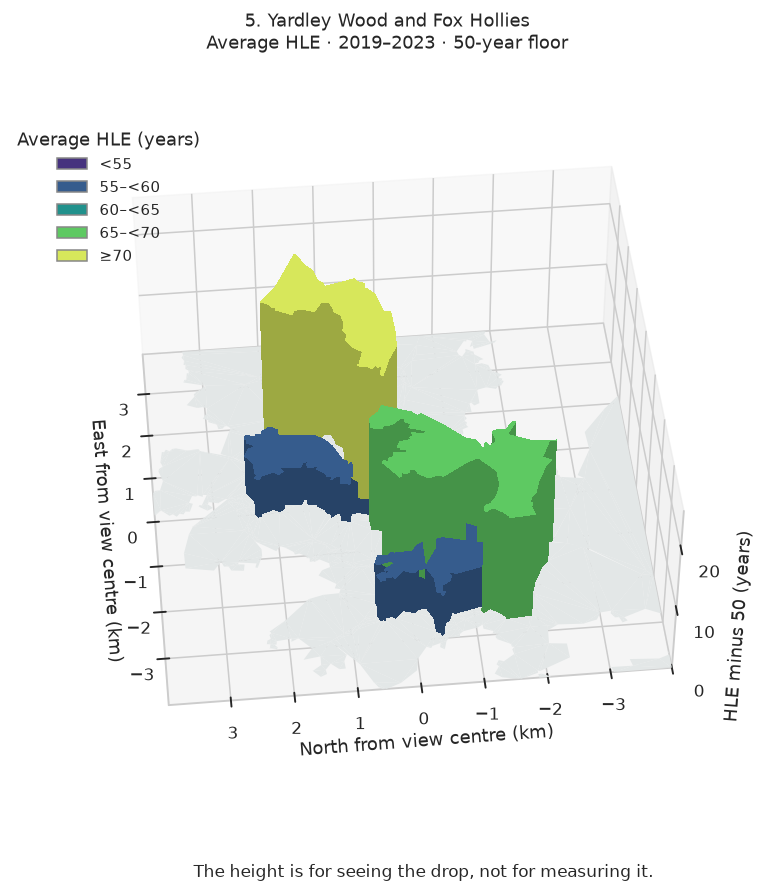

In [37]:
preview_3d(5)

## 5. Looking wider: a Census screen

Everything so far has looked where I expected to find answers: income, qualifications, work, housing, air, crime. That's fine, but it means I only find what I already thought to look for.

So for this last part I look wider. The Census publishes dozens of topics for every MSOA, all from the same day in March 2021. I take nearly all of them and test each one against what the Notebook 05 model couldn't explain: the residuals. I don't test them against HLE itself, because almost everything at area level tracks income, and I'd just find income again a hundred times over.

Testing hundreds of things at once has a catch. Some will look important by pure chance. So I find candidates in half of the local authorities, and I only keep the ones that show up again in the other half.

### What goes in, and what stays out

The Census tables come from the [Nomis Census 2021 bulk files](https://www.nomisweb.co.uk/sources/census_2021_bulk), one zip per topic, and I keep only the rows for my 660 areas. They all describe the same day, 21 March 2021, and they're under the Open Government Licence. If a zip is already in the raw folder I use it; if it isn't, the notebook downloads it there once. A small source register sits beside them.

Some topics I leave out on purpose. The important ones are health, disability and unpaid care. HLE is built from people saying how healthy they are, so testing those against it would just hand HLE its own answers back. One category inside the economic activity table gets the same treatment: people out of work because they're long-term sick or disabled. That's health by another name. Left in, it comes out as the strongest result in the whole screen, which is exactly the problem.

The rest are Welsh-only tables, detailed versions of topics I already have, counts too small to trust, and sensitive topics where the numbers per area are tiny.

In [38]:
from datetime import datetime, timezone
from urllib.request import Request, urlopen
import io
import zipfile

from scipy.stats import spearmanr, false_discovery_control
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_squared_error

In [39]:
# The topics I leave out, and why.
excluded_topics = pd.DataFrame([
    {"Tables": "TS037, TS037ASP, TS038, TS038ASP, TS039, TS039ASP, TS040",
     "Why I leave them out": "General health, disability and unpaid care: HLE ingredients or close to them."},
    {"Tables": "TS011",
     "Why I leave them out": "Household deprivation includes health and disability, as in Notebook 05's exclusion."},
    {"Tables": "TS066: long-term sick or disabled only",
     "Why I leave them out": "Out of work because of illness or disability: health by another name. "
                             "The rest of TS066 stays."},
    {"Tables": "TS032–TS036, TS076",
     "Why I leave them out": "Welsh language: not relevant to this England study."},
    {"Tables": "TS007, TS009, TS012, TS013, TS022, TS024, TS028, TS031, TS064",
     "Why I leave them out": "Detailed versions: hundreds of small categories; broad versions cover the topics."},
    {"Tables": "TS020, TS047, TS048, TS055, TS073",
     "Why I leave them out": "Communal establishments, short-term residents and second-address purpose: tiny counts."},
    {"Tables": "TS070, TS077, TS078, TS079",
     "Why I leave them out": "Sexual orientation and gender identity: small, sensitive counts, "
                             "with ONS quality concerns about gender identity."}])
display(HTML(excluded_topics.to_html(index=False, border=0)))

Tables,Why I leave them out
"TS037, TS037ASP, TS038, TS038ASP, TS039, TS039ASP, TS040","General health, disability and unpaid care: HLE ingredients or close to them."
TS011,"Household deprivation includes health and disability, as in Notebook 05's exclusion."
TS066: long-term sick or disabled only,Out of work because of illness or disability: health by another name. The rest of TS066 stays.
"TS032–TS036, TS076",Welsh language: not relevant to this England study.
"TS007, TS009, TS012, TS013, TS022, TS024, TS028, TS031, TS064",Detailed versions: hundreds of small categories; broad versions cover the topics.
"TS020, TS047, TS048, TS055, TS073","Communal establishments, short-term residents and second-address purpose: tiny counts."
"TS070, TS077, TS078, TS079","Sexual orientation and gender identity: small, sensitive counts, with ONS quality concerns about gender identity."


In [40]:
# The tables I screen. Table order matters: when two variables are near-twins, the earlier one stays.
CENSUS_TITLES = {
    "TS001": "Number of usual residents in households and communal establishments",
    "TS002": "Legal partnership status", "TS003": "Household composition",
    "TS004": "Country of birth", "TS005": "Passports held", "TS006": "Population density",
    "TS007A": "Age by five-year age bands", "TS008": "Sex", "TS010": "Living arrangements",
    "TS015": "Year of arrival in UK", "TS016": "Length of residence", "TS017": "Household size",
    "TS018": "Age of arrival in the UK", "TS019": "Migrant indicator", "TS021": "Ethnic group",
    "TS023": "Multiple ethnic group", "TS025": "Household language", "TS026": "Multiple main languages in households",
    "TS027": "National identity - UK", "TS029": "Proficiency in English", "TS030": "Religion",
    "TS075": "Multi religion households", "TS044": "Accommodation type", "TS045": "Car or van availability",
    "TS046": "Central heating", "TS050": "Number of bedrooms", "TS051": "Number of rooms",
    "TS052": "Occupancy rating for bedrooms", "TS053": "Occupancy rating for rooms", "TS054": "Tenure",
    "TS056": "Second address indicator", "TS058": "Distance travelled to work", "TS059": "Hours worked",
    "TS060": "Industry", "TS061": "Method of travel to work", "TS062": "NS-SeC", "TS063": "Occupation",
    "TS065": "Unemployment history", "TS066": "Economic activity status", "TS067": "Highest level of qualification",
    "TS068": "Schoolchildren and full-time students", "TS071": "Previously served in the UK armed forces",
    "TS072": "Number of people in household who have previously served in UK armed forces",
    "TS074": "Household Reference Person indicator of previous service in UK armed forces"}
assert len(CENSUS_TITLES) == 44

# The source register keeps the date each file was first retrieved; a rerun keeps that date.
screen_source_path = project_data("Raw/Nomis/census_screen_sources.csv")
previous_retrievals = (pd.read_csv(screen_source_path).set_index("table")["date_retrieved"].to_dict()
                       if screen_source_path.is_file() else {})
retrieval_date = datetime.now(timezone.utc).date().isoformat()

study_codes = pd.Index(areas["area_code"], name="area_code")
model_codes = pd.Index(model_areas["area_code"], name="area_code")

# These fill up as each table is read: the values, a description of each variable, and the source records.
census_values = {}
variable_rows, source_rows, source_audit_rows = [], [], []

In [41]:
for table_code, title in CENSUS_TITLES.items():
    filename = f"census2021-{table_code.lower()}.zip"
    url = "https://www.nomisweb.co.uk/output/census/2021/" + filename

    # Use the zip already in the raw folder if there is one; only download what's missing.
    matches = sorted(project_data("Raw").rglob(filename))
    assert len(matches) <= 1, f"More than one raw file has the name {filename}"
    download_status = "reused" if matches else "downloaded"
    if not matches:
        try:
            with urlopen(Request(url, headers={"User-Agent": "Birmingham-HLE-Census-screen/1.0"}),
                         timeout=90) as response:
                payload = response.read()
            # Check it is a zip before saving; never overwrite an existing source.
            with zipfile.ZipFile(io.BytesIO(payload)) as archive:
                assert archive.namelist(), "Empty zip"
            destination = project_data("Raw/Nomis") / filename
            destination.parent.mkdir(parents=True, exist_ok=True)
            with destination.open("xb") as stream:
                stream.write(payload)
        except Exception as error:
            source_audit_rows.append({"table": table_code, "source_status": "failed",
                "source_note": f"Download failed: {type(error).__name__}: {error}"})
            continue

    # Each zip holds one CSV per geography. I only want the MSOA one.
    with zipfile.ZipFile(raw_file(filename)) as archive:
        expected_member = f"census2021-{table_code.lower()}-msoa.csv"
        # Nomis TS002 has a double dot before csv; keep the genuine MSOA member.
        members = [name for name in archive.namelist() if name.replace("..csv", ".csv") == expected_member]
        if len(members) != 1:
            source_audit_rows.append({"table": table_code, "source_status": "skipped",
                                      "source_note": "No unique MSOA CSV member"})
            continue
        with archive.open(members[0]) as stream:
            census_table = pd.read_csv(stream, encoding="utf-8-sig")

    # Keep my 660 areas, and check every one is there and dated 2021.
    assert census_table["geography code"].is_unique, table_code
    census_table = census_table.set_index("geography code")
    assert set(study_codes) <= set(census_table.index), f"Missing study codes in {table_code}"
    census_table = census_table.loc[study_codes]
    assert len(census_table) == EXPECTED_AREAS
    assert census_table["date"].astype(str).str.startswith("2021").all(), table_code

    # The first column with "Total" in its name is the denominator for every category in the table.
    # Density is already a rate, so it has none.
    value_columns = [column for column in census_table if column not in ["date", "geography"]]
    total_columns = [column for column in value_columns if "total" in column.lower()]
    if table_code == "TS006":
        assert len(value_columns) == 1 and not total_columns
        denominator_label = "Not applicable: density retained in persons per square kilometre"
        categories = value_columns
    elif not total_columns:
        source_audit_rows.append({"table": table_code, "source_status": "skipped",
                                  "source_note": "No Total denominator column"})
        continue
    else:
        denominator_label = total_columns[0]
        denominator_values = pd.to_numeric(census_table[denominator_label], errors="raise")
        assert denominator_values.notna().all() and denominator_values.gt(0).all(), table_code
        categories = [column for column in value_columns if column != denominator_label]
        # Usual residents from the age table are the denominator for takeaways later.
        if table_code == "TS007A":
            census_residents = denominator_values.copy()

    source_rows.append({"table": table_code, "title": title, "URL": url,
        "date_retrieved": str(previous_retrievals.get(table_code, retrieval_date)),
        "licence": "Open Government Licence v3.0", "reference_date": "2021-03-21"})
    source_audit_rows.append({"table": table_code, "source_status": download_status,
        "source_note": "MSOA member has Nomis's double-dot filename" if members[0] != expected_member else "Used"})

    # Every category becomes a percentage of the table's total, with a stable id: table code plus position.
    for position, category in enumerate(categories, start=1):
        counts = pd.to_numeric(census_table[category], errors="raise")
        assert counts.notna().all() and counts.ge(0).all(), (table_code, category)
        values = counts if table_code == "TS006" else 100 * counts / denominator_values
        variable_id = f"{table_code}__{position:03d}"

        # The readable label is the last step of the category's hierarchy.
        clean_category = category.split("; measures:")[0].strip()
        label = table_code + " · " + clean_category.split(":")[-1].strip()
        variable_unit = "persons/km²" if table_code == "TS006" else "% of table total"
        census_values[variable_id] = values
        does_not_apply = "does not apply" in category.lower()

        variable_rows.append({"variable_id": variable_id, "table": table_code, "label": label,
            "category": category, "denominator": denominator_label, "variable_unit": variable_unit,
            "study_median": float(values.median()), "nonmissing_count": int(values.notna().sum()),
            "selection_status": "dropped" if does_not_apply else "pending",
            "drop_reason": "Does not apply" if does_not_apply else "Not applicable", "twin_of": "Not applicable",
            "is_top_level_ethnicity": table_code == "TS021" and clean_category.count(":") == 1})

census_sources = pd.DataFrame(source_rows)
census_source_audit = pd.DataFrame(source_audit_rows)
assert "TS007A" in set(census_sources["table"]), "TS007A residents are needed for takeaways"

display(census_source_audit)

,table,source_status,source_note
0,TS001,reused,Used
1,TS002,reused,MSOA member has Nomis's double-dot filename
2,TS003,reused,Used
3,TS004,reused,Used
4,TS005,reused,Used
5,TS006,reused,Used
6,TS007A,reused,Used
7,TS008,skipped,No Total denominator column
8,TS010,reused,Used
9,TS015,reused,Used


### Turning counts into shares

Raw counts mostly tell me how big an area is, so each category becomes a share of its table's total: the percentage of residents, or of households, that fall into it. Population density stays as people per square kilometre.

Then I thin the list. A category that's under 1% in a typical area goes, because a handful of people can swing it. So do near-copies: where two variables put the areas in almost exactly the same order (Spearman 0.98 or more), I keep the first and drop the second.

I add one thing that isn't from the Census: takeaways per 1,000 residents, from the [Food environment assessment tool (FEAT)](https://www.feat-tool.org.uk/), MRC Epidemiology Unit, University of Cambridge, June 2023 snapshot, Open Government Licence. It uses the older 2011 area codes, which match 651 of my 660 areas. The nine that were redrawn stay blank rather than being counted as having no takeaways.

The other files I copied in for this notebook stay out. Obesity and the drug, alcohol and suicide death rates are health outcomes in their own right, smoking only exists for whole authorities, and IMD 2025 has health built into it.

In [42]:
# Takeaways per 1,000 residents, from FEAT. It uses 2011 area codes, which match 651 of my 660.
feat = pd.read_csv(raw_file("feat_fast_food_msoa_2023-06-01.csv"))

# The national extract repeats placeholder codes outside this study; validate only matched areas.
feat = feat.loc[feat["code"].isin(study_codes)].copy()
assert feat["code"].is_unique

# The nine redrawn areas stay blank. A missing count isn't the same as no takeaways.
feat_counts = feat.set_index("code")["takeaway"].reindex(study_codes)
feat_missing_codes = sorted(feat_counts.index[feat_counts.isna()])
assert feat_counts.notna().sum() == 651
assert feat_missing_codes == sorted(["E02006943", "E02006944", "E02006982", "E02007038", "E02007039",
    "E02007040", "E02007048", "E02007050", "E02007051"])
assert feat_counts.dropna().ge(0).all()

takeaways_id = "FEAT__takeaways_per_1000"
census_values[takeaways_id] = 1000 * feat_counts / census_residents
variable_rows.append({"variable_id": takeaways_id, "table": "FEAT",
    "label": "FEAT · Takeaways per 1,000 residents", "category": "takeaway",
    "denominator": "TS007A Age: Total; Census 2021 usual residents", "variable_unit": "takeaways/1,000 residents",
    "study_median": float(census_values[takeaways_id].median()), "nonmissing_count": int(feat_counts.notna().sum()),
    "selection_status": "pending", "drop_reason": "Not applicable", "twin_of": "Not applicable",
    "is_top_level_ethnicity": False})

# All the screen's values in one table (areas down, variables across), and a description of each variable.
screen_values = pd.DataFrame(census_values, index=study_codes)
census_screen_variables = pd.DataFrame(variable_rows)

In [43]:
# Some leaves repeat under different parents, even with opposite findings. Name the parent then.
# I add one step of the parent's name at a time until every label is different.
for label, repeated in census_screen_variables.groupby("label", sort=False):
    if len(repeated) < 2:
        continue
    paths = {position: [part.strip() for part in row["category"].split("; measures:")[0].split(":")]
             for position, row in repeated.iterrows()}
    for depth in range(2, max(len(path) for path in paths.values()) + 1):
        alternatives = {position: label + " (" + " / ".join(path[-depth:-1]) + ")"
                        for position, path in paths.items()}
        if len(set(alternatives.values())) == len(alternatives):
            break
    if len(set(alternatives.values())) < len(alternatives):
        # TS027 repeats one category with trailing whitespace; retain both in the audit until twin removal.
        alternatives = {position: readable + f" [source column {position + 1}]"
                        for position, readable in alternatives.items()}
    for position, readable_label in alternatives.items():
        census_screen_variables.loc[position, "label"] = readable_label

assert census_screen_variables["label"].is_unique

In [44]:
# One category inside an otherwise useful table is health by another name, so it goes the way of TS037–TS040.
health_category = census_screen_variables["variable_id"].eq("TS066__029")
assert health_category.sum() == 1
assert census_screen_variables.loc[health_category, "label"].eq("TS066 · Long-term sick or disabled").all()
census_screen_variables.loc[health_category, ["selection_status", "drop_reason"]] = [
    "dropped", "Health-related category"]

# Keep the 1% rule for Census shares; density and the extra takeaway rate are not percentages.
tiny = (census_screen_variables["selection_status"].eq("pending")
        & census_screen_variables["variable_unit"].eq("% of table total")
        & census_screen_variables["study_median"].lt(1))
census_screen_variables.loc[tiny, ["selection_status", "drop_reason"]] = ["dropped", "Study-area median below 1%"]

# Near-twins: if a variable ranks the areas almost exactly as an earlier one does (0.98 or more), it goes.
available_ids = (census_screen_variables
                 .loc[census_screen_variables["selection_status"].eq("pending"), "variable_id"].tolist())
twins = screen_values.loc[model_codes, available_ids].corr(method="spearman")
kept_ids = []

for variable_id in available_ids:
    earlier_twins = [earlier for earlier in kept_ids if abs(twins.loc[variable_id, earlier]) >= 0.98]
    row = census_screen_variables["variable_id"].eq(variable_id)
    if earlier_twins:
        census_screen_variables.loc[row, ["selection_status", "drop_reason", "twin_of"]] = [
            "dropped", "Absolute Spearman with an earlier retained variable >= 0.98", earlier_twins[0]]
    else:
        kept_ids.append(variable_id)
        census_screen_variables.loc[row, "selection_status"] = "kept"

screen_metadata = census_screen_variables.set_index("variable_id")

In [45]:
# How many variables each step built, dropped and kept.
screen_counts = pd.DataFrame([
    {"step": "Census tables used", "count": len(census_sources)},
    {"step": "Census variables built", "count": int(census_screen_variables["table"].ne("FEAT").sum())},
    {"step": "Extra takeaway candidate", "count": 1},
    {"step": "Variables built, total", "count": len(census_screen_variables)},
    {"step": "Dropped: Does not apply",
     "count": int(census_screen_variables["drop_reason"].eq("Does not apply").sum())},
    {"step": "Dropped: health-related category", "count": int(health_category.sum())},
    {"step": "Dropped: median below 1%", "count": int(tiny.sum())},
    {"step": "Dropped: near-twins",
     "count": int(census_screen_variables["twin_of"].ne("Not applicable").sum())},
    {"step": "Tested", "count": len(kept_ids)}])

assert (len(census_screen_variables)
        == len(kept_ids) + census_screen_variables["selection_status"].eq("dropped").sum())
assert len(kept_ids) == len(set(kept_ids))

display(screen_counts)
print("Takeaway blanks:", ", ".join(feat_missing_codes))

,step,count
0,Census tables used,43
1,Census variables built,512
2,Extra takeaway candidate,1
3,"Variables built, total",513
4,Dropped: Does not apply,0
5,Dropped: health-related category,1
6,Dropped: median below 1%,221
7,Dropped: near-twins,43
8,Tested,248


Takeaway blanks: E02006943, E02006944, E02006982, E02007038, E02007039, E02007040, E02007048, E02007050, E02007051


### Finding in one half, checking in the other

I split the 37 local authorities into two halves with the same number of areas, 327 each, keeping every authority whole. Birmingham, Wolverhampton and Solihull land in the first half; Dudley, Coventry, Sandwell and Walsall in the second.

For each characteristic the question is simple. Do areas with more of it tend to sit above the model's prediction, or below it? Spearman correlation answers that by ranking the areas on both and seeing whether the rankings agree. Positive means more of it goes with HLE higher than predicted. Negative means lower.

With this many tests, some will come up by chance. The Benjamini–Hochberg adjustment raises the bar to allow for how many things I've tested. Anything that clears it in the first half becomes a candidate. A candidate only counts as confirmed if it clears the bar again in the second half and points the same way.

In [46]:
# Split the authorities into two halves with equal numbers of areas, keeping each authority whole.
# Largest first, each goes into whichever half is smaller so far.
authority_sizes = (model_areas.groupby(["authority_code", "authority_name"]).size()
                   .rename("area_count").reset_index()
                   .sort_values(["area_count", "authority_code"], ascending=[False, True]).reset_index(drop=True))
assert len(authority_sizes) == 37

half_totals = {"A": 0, "B": 0}
half_by_authority = {}

for row in authority_sizes.itertuples():
    half = "A" if half_totals["A"] <= half_totals["B"] else "B"
    half_by_authority[row.authority_code] = half
    half_totals[half] += row.area_count

authority_sizes["half"] = authority_sizes["authority_code"].map(half_by_authority)
model_halves = model_areas.set_index("area_code")["authority_code"].map(half_by_authority)
half_codes = {half: model_halves.index[model_halves.eq(half)] for half in ["A", "B"]}

# No area in both halves, and none left out.
assert not set(half_codes["A"]) & set(half_codes["B"])
assert set(half_codes["A"]) | set(half_codes["B"]) == set(model_codes)

display(authority_sizes[["half", "authority_name", "area_count"]]
        .sort_values(["half", "area_count", "authority_name"], ascending=[True, False, True])
        .reset_index(drop=True))
display(authority_sizes.groupby("half").agg(authorities=("authority_code", "size"), areas=("area_count", "sum")))

,half,authority_name,area_count
0,A,Birmingham,129
1,A,Wolverhampton,32
2,A,Solihull,29
3,A,Derby,16
4,A,East Staffordshire,15
5,A,Warwick,15
6,A,Wyre Forest,14
7,A,Cannock Chase,13
8,A,Redditch,13
9,A,Hinckley and Bosworth,12


,authorities,areas
half,,
A,17,327
B,20,327


In [47]:
# The thing being screened: Notebook 05's residual, what the seven measures couldn't explain.
residual_target = model_areas.set_index("area_code")["residual"]


# Spearman correlation of one variable with the residual, in the areas given. Blanks are left out.
# A variable that's the same everywhere has no correlation, so it can't become a candidate.
def residual_correlation(variable_id, codes):
    x = screen_values.loc[codes, variable_id]
    target = residual_target.loc[codes]
    present = x.notna() & target.notna()
    n = int(present.sum())
    if n < 3 or x.loc[present].nunique() < 2 or target.loc[present].nunique() < 2:
        return np.nan, 1.0, n
    result = spearmanr(x.loc[present], target.loc[present])
    return float(result.statistic), float(result.pvalue), n


# Step 1: test every kept variable in half A. The full-sample correlation is for description only.
result_rows = []

for variable_id in kept_ids:
    rho_a, p_a, n_a = residual_correlation(variable_id, half_codes["A"])
    full_rho, _, n_full = residual_correlation(variable_id, model_codes)
    result_rows.append({"variable_id": variable_id, "table": screen_metadata.loc[variable_id, "table"],
        "label": screen_metadata.loc[variable_id, "label"], "half_a_n": n_a, "half_a_rho": rho_a,
        "half_a_p": p_a, "half_a_adjusted_p": np.nan, "half_b_n": np.nan,
        "half_b_rho": np.nan, "half_b_p": np.nan, "half_b_adjusted_p": np.nan,
        "full_sample_n": n_full, "full_sample_rho": full_rho, "status": "not a candidate"})

census_screen_results = pd.DataFrame(result_rows)

# Benjamini–Hochberg raises the bar to allow for how many tests I've run.
census_screen_results["half_a_adjusted_p"] = false_discovery_control(
    census_screen_results["half_a_p"].to_numpy(), method="bh")
candidate_mask = census_screen_results["half_a_adjusted_p"].lt(0.05)
candidate_ids = census_screen_results.loc[candidate_mask, "variable_id"].tolist()
census_screen_results.loc[candidate_mask, "status"] = "candidate not confirmed"

# Step 2: test only the candidates in half B, and adjust again across just those.
for position in census_screen_results.index[candidate_mask]:
    variable_id = census_screen_results.loc[position, "variable_id"]
    rho_b, p_b, n_b = residual_correlation(variable_id, half_codes["B"])
    census_screen_results.loc[position, ["half_b_rho", "half_b_p", "half_b_n"]] = [rho_b, p_b, n_b]

if candidate_ids:
    census_screen_results.loc[candidate_mask, "half_b_adjusted_p"] = false_discovery_control(
        census_screen_results.loc[candidate_mask, "half_b_p"].to_numpy(), method="bh")

# Confirmed means: clears the bar in A, clears it again in B, and points the same way in both.
confirmed_mask = (candidate_mask & census_screen_results["half_b_adjusted_p"].lt(0.05)
                  & np.sign(census_screen_results["half_a_rho"]).eq(np.sign(census_screen_results["half_b_rho"])))
census_screen_results.loc[confirmed_mask, "status"] = "confirmed"

confirmed_results = (census_screen_results.loc[confirmed_mask]
                     .sort_values("full_sample_rho", key=abs, ascending=False).reset_index(drop=True))
assert confirmed_results["half_a_adjusted_p"].lt(0.05).all() and confirmed_results["half_b_adjusted_p"].lt(0.05).all()
assert np.sign(confirmed_results["half_a_rho"]).eq(np.sign(confirmed_results["half_b_rho"])).all()

In [48]:
print(f"{len(kept_ids)} tests in A → {len(candidate_ids)} candidates → {len(confirmed_results)} confirmed in B.")

confirmed_display = confirmed_results[["label", "half_a_rho", "half_a_adjusted_p", "half_b_rho",
                                       "half_b_adjusted_p", "full_sample_rho"]].copy()

for column in ["half_a_rho", "half_b_rho", "full_sample_rho"]:
    confirmed_display[column] = confirmed_display[column].round(4)

# Adjusted p-values can be tiny, so they're shown to three significant figures.
display(HTML('<div style="max-width:100%;overflow-x:auto">' + confirmed_display.to_html(index=False, border=0,
    formatters={"half_a_adjusted_p": lambda value: f"{value:.3g}",
                "half_b_adjusted_p": lambda value: f"{value:.3g}"}) + '</div>'))

248 tests in A → 95 candidates → 81 confirmed in B.


label,half_a_rho,half_a_adjusted_p,half_b_rho,half_b_adjusted_p,full_sample_rho
TS002 · Married or in a registered civil partnership,0.3410,1.99e-08,0.3638,2.16e-10,0.3519
TS054 · Owns outright,0.2768,4.61e-06,0.3964,8.94e-12,0.3349
TS003 · All children non-dependent (Married or civil partnership couple),0.2978,7.12e-07,0.3681,2.16e-10,0.3338
TS010 · Married or in a civil partnership,0.2989,6.79e-07,0.3432,1.9e-09,0.3184
TS075 · Same religion (at least one person has stated a religion but the household may include people who did not state their religion),0.3443,1.94e-08,0.2837,7.26e-07,0.3126
TS062 · L8 and L9 Small employers and own account workers,0.3215,8.23e-08,0.3022,1.41e-07,0.3125
TS002 · Never married and never registered a civil partnership,-0.2822,3.07e-06,-0.3512,8.58e-10,-0.3117
TS054 · Rents from council or Local Authority,-0.3543,1.03e-08,-0.2479,1.55e-05,-0.3081
TS003 · Other,-0.3009,6.46e-07,-0.2859,6.19e-07,-0.2993
TS054 · Social rented,-0.3206,8.23e-08,-0.2671,3.5e-06,-0.2986


### What survived

248 characteristics went in. 95 cleared the bar in the first half, and 81 of those held up in the second. That's far more than I expected, and it made me suspicious. I come back to it below.

The chart shows the ten strongest each way. On the plus side are married couples, owning outright, couples whose children have grown up, and small employers and the self-employed. On the minus side are people who've never married, renting from the council or a housing association, people under 66 living alone, and people in their early thirties. Areas with more of the first sit above the model's prediction. Areas with more of the second sit below it.

"Lives in a household" is the flip side of communal living: care homes, student halls, hostels. Areas with more people living communally sit below prediction.

Takeaways didn't make it. They don't clear the bar in the first half (adjusted p 0.10), and what little link there is runs slightly positive.

In [49]:
# A few source categories mean nothing without their parent, so they get a plain name for the chart.
PLAIN_NAMES = {
    "TS003__003": "One-person household, under 66",
    "TS003__019": "Other household types",
    "TS052__001": "Two or more spare bedrooms", "TS052__002": "One spare bedroom",
    "TS052__003": "Just enough bedrooms", "TS052__004": "One bedroom short",
    "TS053__001": "Two or more spare rooms", "TS053__002": "One spare room",
    "TS053__003": "Just enough rooms", "TS053__004": "One room short"}


# A chart label: the category's plain name, then the Census topic it comes from.
def plain_label(variable_id):
    table = screen_metadata.loc[variable_id, "table"]
    if variable_id in PLAIN_NAMES:
        leaf = PLAIN_NAMES[variable_id]
    else:
        leaf = screen_metadata.loc[variable_id, "label"].split(" · ", 1)[1]
    topic = CENSUS_TITLES.get(table, "Food environment")
    return f"{leaf}  ·  {topic}"

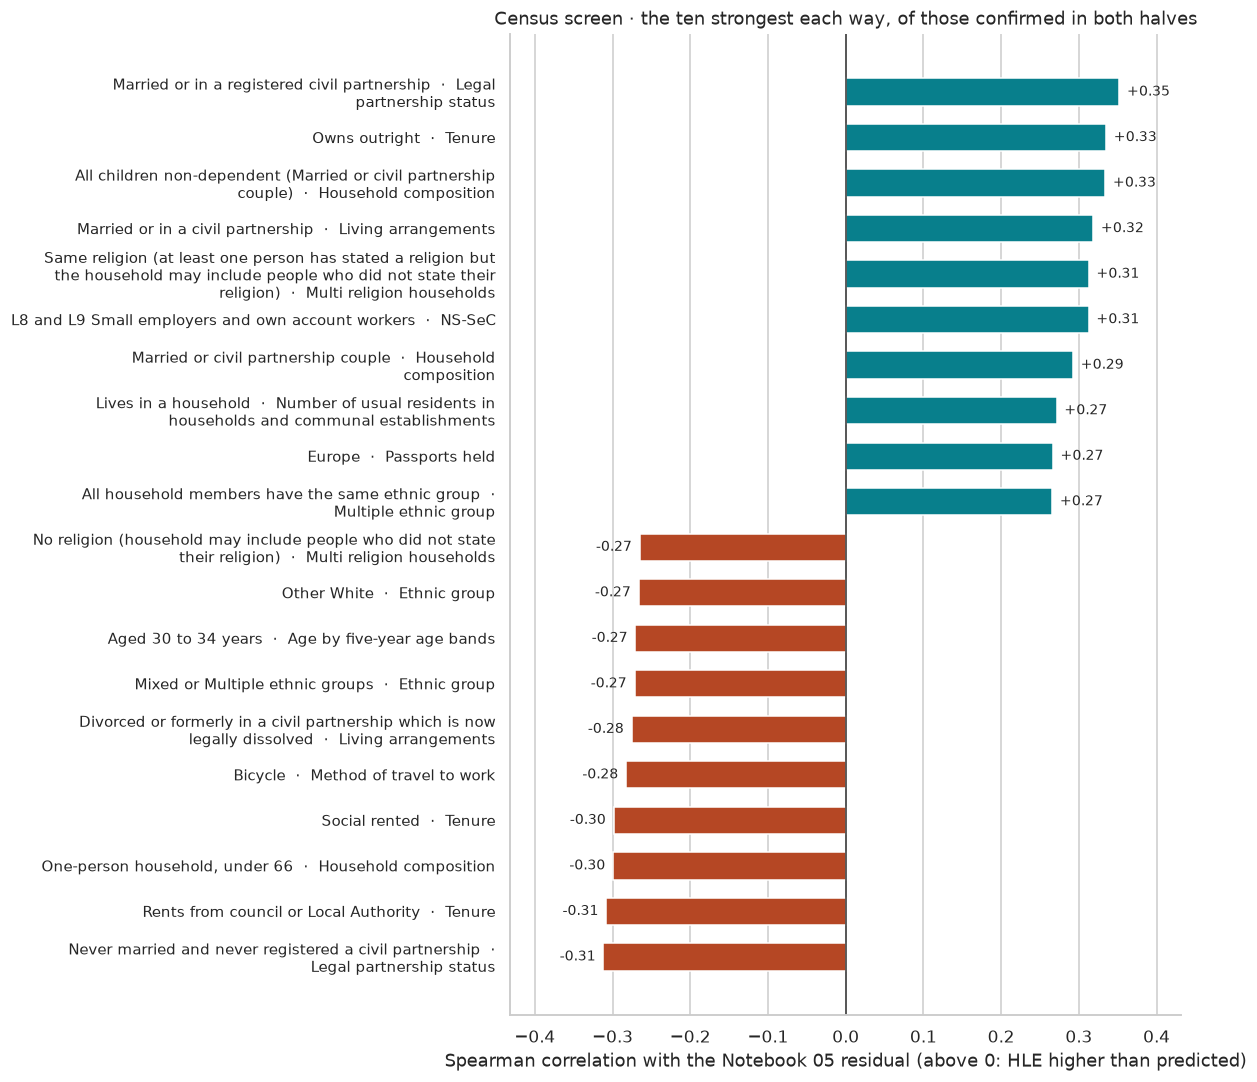

Showing 20 of 81 confirmed characteristics.


In [50]:
# The ten strongest each way. If nothing were confirmed, the chart would say so in its title.
if len(confirmed_results):
    ranked = confirmed_results.sort_values("full_sample_rho")
    plot_results = pd.concat([ranked.head(10), ranked.tail(10)]).drop_duplicates("variable_id")
    rho_column = "full_sample_rho"
    title = "Census screen · the ten strongest each way, of those confirmed in both halves"
else:
    plot_results = census_screen_results.sort_values("half_a_adjusted_p").head(20).sort_values("half_a_rho")
    rho_column = "half_a_rho"
    title = "Census screen · top 20 finding-half results · NOT CONFIRMED"

labels = [textwrap.fill(plain_label(v), 60) for v in plot_results["variable_id"]]

fig, ax = plt.subplots(figsize=(11, 0.42 * len(plot_results) + 1.6))

# Teal for above prediction, rust for below.
colours = ["#087f8c" if value >= 0 else "#b54724" for value in plot_results[rho_column]]
ax.barh(range(len(plot_results)), plot_results[rho_column], color=colours, height=0.6)
ax.set_yticks(range(len(plot_results)), labels, fontsize=9.5)
ax.axvline(0, color="#333333", linewidth=1)

for position, rho in enumerate(plot_results[rho_column]):
    ax.text(rho + (0.01 if rho >= 0 else -0.01), position, f"{rho:+.2f}",
            ha="left" if rho >= 0 else "right", va="center", fontsize=9)

extent = float(plot_results[rho_column].abs().max()) + 0.08
ax.set(xlim=(-extent, extent),
       xlabel="Spearman correlation with the Notebook 05 residual (above 0: HLE higher than predicted)",
       title=title)
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_figure(fig, "04_census_screen_correlations.png")

print(f"Showing {len(plot_results)} of {len(confirmed_results)} confirmed characteristics.")

### Eighty-one things, or one?

Area characteristics travel together. An area with lots of married couples tends to have lots of owners, more cars, more spare bedrooms and fewer people renting. So I combine the 81 confirmed characteristics into a single score (principal components, run on the rankings) and see how much of their spread it carries. The table shows the six that line up most closely with each end of it.

In [51]:
# How many separate ideas are in the confirmed list?
# If one combined score carries most of their spread, it's mostly one picture.
from sklearn.decomposition import PCA

# Ranks, then standardised, so every characteristic counts equally whatever its units.
confirmed_ids = confirmed_results["variable_id"].tolist()
confirmed_ranks = screen_values.loc[model_codes, confirmed_ids].rank()
confirmed_scaled = (confirmed_ranks - confirmed_ranks.mean()) / confirmed_ranks.std()
assert confirmed_scaled.notna().all().all()

# Principal components: the first is the single score that captures the most shared spread.
# The full solver is exact; the default switches to a randomised one at this size, and that varies between runs.
pca = PCA(n_components=3, svd_solver="full").fit(confirmed_scaled)
first_score = pd.Series(pca.transform(confirmed_scaled)[:, 0], index=model_codes)

# Point the score so that a higher value means more owner-occupied, settled households.
if spearmanr(first_score, screen_values.loc[model_codes, "TS054__002"]).statistic < 0:
    first_score = -first_score

# How closely each characteristic lines up with the score.
loading = confirmed_scaled.corrwith(first_score)
one_picture = {
    "first_share": float(pca.explained_variance_ratio_[0]),
    "second_share": float(pca.explained_variance_ratio_[1]),
    "strongly_aligned": int(loading.abs().ge(0.5).sum()),
    "score_residual_rho": float(spearmanr(first_score, residual_target.loc[model_codes]).statistic)}

ends = pd.DataFrame({"label": [plain_label(v) for v in loading.index], "alignment": loading.round(2)})
display(pd.concat([ends.sort_values("alignment").head(6), ends.sort_values("alignment").tail(6)])
        .reset_index(drop=True))

print(f"One combined score carries {one_picture['first_share']:.0%} of the spread across the "
      f"{len(confirmed_ids)} confirmed characteristics; the next carries {one_picture['second_share']:.0%}.")
print(f"{one_picture['strongly_aligned']} of them line up with it at 0.5 or more either way.")
print(f"The score's own correlation with the residual: {one_picture['score_residual_rho']:+.2f}")

,label,alignment
0,Just enough bedrooms · Occupancy rating for ...,-0.96
1,No cars or vans in household · Car or van av...,-0.95
2,Single (never married and never registered a s...,-0.93
3,Never married and never registered a civil par...,-0.92
4,Just enough rooms · Occupancy rating for rooms,-0.92
5,Unemployed (Economically active (excluding ful...,-0.92
6,Two or more spare rooms · Occupancy rating f...,0.92
7,Owned · Tenure,0.93
8,Living in a couple · Living arrangements,0.94
9,3 or more cars or vans in household · Car or...,0.95


One combined score carries 51% of the spread across the 81 confirmed characteristics; the next carries 13%.
62 of them line up with it at 0.5 or more either way.
The score's own correlation with the residual: +0.30


One score carries 51% of the spread across all 81, and the next carries only 13%. 62 of the 81 line up with it strongly. One end is owning, couples, cars and spare rooms. The other is single people, no car and only just enough bedrooms.

So most of the screen's result is one picture. Areas of settled, owner-occupied households do better than income, qualifications and the rest would predict, and areas of single people renting do worse. The model already has income in it. Owning outright is nearer to wealth than income, and that may be part of it, but the Census can't tell me why.

### Does it help the model?

If these characteristics carry something the seven measures miss, adding one should improve the predictions. I take the strongest five, but only one from each table, and I skip any that mostly repeat one I've already picked (0.9 or more), so the two near-identical "married" variables don't both go in. Each goes into the Notebook 05 model on its own, with the same five batches of whole authorities held out. First I rebuild the original model and check it gives exactly the same predictions as Notebook 05.

In [52]:
# Rebuild Notebook 05's test: the same areas, the same five batches of whole authorities held out.
cv_areas = model_areas.reset_index(drop=True)
cv_groups = cv_areas["authority_code"].to_numpy()
cv_y = cv_areas["hle_average"].to_numpy()
cv_X = cv_areas[features]
cv_folds = list(GroupKFold(n_splits=5).split(cv_X, cv_y, cv_groups))

# Each batch must hold out exactly the authorities Notebook 05 held out.
saved_05_summary = json.loads(project_data("Cleaned/Machine Learning/results_summary.json").read_text())

for fold_number, (_, test) in enumerate(cv_folds, start=1):
    expected_authorities = saved_05_summary["folds"][fold_number - 1]["test_authorities"].split("; ")
    assert sorted(cv_areas.iloc[test]["authority_name"].unique()) == expected_authorities

In [53]:
# Train on four batches, predict the fifth, five times over, then score every prediction together.
# "included" lets a variable with blanks be scored on only its complete areas.
def grouped_score(predictors, included=None):
    included = np.ones(len(cv_areas), dtype=bool) if included is None else np.asarray(included)
    predictions = np.full(len(cv_areas), np.nan)

    for training, test in cv_folds:
        training = training[included[training]]
        test = test[included[test]]
        assert not set(cv_groups[training]) & set(cv_groups[test])
        assert len(training) and len(test), "A complete-case fold has no training or test areas"

        # Scaling sits inside the pipeline, so it learns only from the training batches.
        regression = Pipeline([("scale", StandardScaler()), ("linear", LinearRegression())])
        regression.fit(predictors.iloc[training], cv_y[training])
        predictions[test] = regression.predict(predictors.iloc[test])

    assert np.isfinite(predictions[included]).all()
    return {"rmse_years": float(np.sqrt(mean_squared_error(cv_y[included], predictions[included]))),
            "r2": float(r2_score(cv_y[included], predictions[included]))}, predictions

In [54]:
# The rebuilt seven-measure model must match Notebook 05 exactly, area by area.
rebuilt_baseline, rebuilt_predictions = grouped_score(cv_X)
assert round(rebuilt_baseline["rmse_years"], 3) == 1.645
assert round(rebuilt_baseline["r2"], 3) == 0.894
assert np.allclose(rebuilt_predictions, cv_areas["out_of_fold_prediction"], atol=1e-9, rtol=0)

model_check_rows = [{"variable_id": "baseline", "label": "Notebook 05 · seven measures",
    "area_count": len(cv_areas), "added_variable": False, **rebuilt_baseline,
    "matched_baseline_rmse_years": rebuilt_baseline["rmse_years"], "matched_baseline_r2": rebuilt_baseline["r2"],
    "rmse_change_years": 0.0, "r2_change": 0.0, "improves_grouped_prediction": False}]

# Five checks should test five ideas: one per table, and nothing that mostly repeats an earlier pick.
top_confirmed_ids = []

for row in confirmed_results.itertuples():
    if len(top_confirmed_ids) == 5:
        break
    if row.table in set(screen_metadata.loc[top_confirmed_ids, "table"]):
        continue
    if any(abs(twins.loc[row.variable_id, picked]) >= 0.9 for picked in top_confirmed_ids):
        continue
    top_confirmed_ids.append(row.variable_id)

# Add each pick on its own to the seven measures, and compare with the baseline on the same areas.
for variable_id in top_confirmed_ids:
    added = screen_values.loc[cv_areas["area_code"], variable_id].to_numpy()
    included = np.isfinite(added)
    extended_X = cv_X.copy()
    extended_X[variable_id] = added
    matched_baseline = rebuilt_baseline if included.all() else grouped_score(cv_X, included)[0]
    score, _ = grouped_score(extended_X, included)

    model_check_rows.append({"variable_id": variable_id, "label": screen_metadata.loc[variable_id, "label"],
        "area_count": int(included.sum()), "added_variable": True, **score,
        "matched_baseline_rmse_years": matched_baseline["rmse_years"],
        "matched_baseline_r2": matched_baseline["r2"],
        "rmse_change_years": score["rmse_years"] - matched_baseline["rmse_years"],
        "r2_change": score["r2"] - matched_baseline["r2"],
        "improves_grouped_prediction": (score["rmse_years"] < matched_baseline["rmse_years"]
                                        and score["r2"] > matched_baseline["r2"])})

census_screen_model_check = pd.DataFrame(model_check_rows)

display(HTML('<div style="max-width:100%;overflow-x:auto">'
             + census_screen_model_check[["label", "area_count", "rmse_years", "r2", "rmse_change_years",
                                          "r2_change", "improves_grouped_prediction"]]
               .round(4).to_html(index=False, border=0)
             + '</div>'))

label,area_count,rmse_years,r2,rmse_change_years,r2_change,improves_grouped_prediction
Notebook 05 · seven measures,654,1.6448,0.8937,0.0000,0.0000,False
TS002 · Married or in a registered civil partnership,654,1.4489,0.9175,-0.1959,0.0238,True
TS054 · Owns outright,654,1.2817,0.9355,-0.3631,0.0417,True
TS003 · All children non-dependent (Married or civil partnership couple),654,1.5239,0.9088,-0.1209,0.0150,True
TS075 · Same religion (at least one person has stated a religion but the household may include people who did not state their religion),654,1.5398,0.9069,-0.1050,0.0131,True
TS062 · L8 and L9 Small employers and own account workers,654,1.5421,0.9066,-0.1027,0.0129,True


All five help. Owning outright helps most: the typical miss drops from 1.64 years to 1.28, and the model accounts for 93.5% of the variation in HLE rather than 89.4%. The married share gets it to 1.45. The other three each get it to around 1.52 to 1.54.

There's a catch, and it matters. I picked these because they line up with the model's misses, so of course they help fix them. Holding out whole authorities still keeps the test honest about places the model hasn't seen, but it isn't a fresh test. I'd want another dataset, or the next Census, before I trusted the size of the gain.

### The ethnic composition question

I wanted to know whether ethnic composition shows up in the screen, so I look at the five top-level ethnic groups whatever happened to them earlier. These are shares of each area's residents. They describe places, not people, and they say nothing about why.

The last numeric column asks what's left of each link once the combined score from above is allowed for.

In [55]:
# Area characteristics travel together. This asks whether an ethnic composition link survives once
# the combined settled-household score is allowed for, using ranks as Spearman does.
# Take out what the score explains from both the share and the residual, then correlate what's left.
def partial_rho(variable_id):
    ranks = pd.DataFrame({"share": screen_values.loc[model_codes, variable_id],
                          "residual": residual_target.loc[model_codes], "score": first_score}).rank()
    leftovers = {}
    for column in ["share", "residual"]:
        fit = LinearRegression().fit(ranks[["score"]], ranks[column])
        leftovers[column] = ranks[column] - fit.predict(ranks[["score"]])
    return float(np.corrcoef(leftovers["share"], leftovers["residual"])[0, 1])


# All five top-level groups, whatever happened to them in the screen.
ethnic_rows = []
results_by_variable = census_screen_results.set_index("variable_id")

for variable_id in census_screen_variables.loc[census_screen_variables["is_top_level_ethnicity"], "variable_id"]:
    meta = screen_metadata.loc[variable_id]
    status = (results_by_variable.loc[variable_id, "status"] if variable_id in results_by_variable.index
              else "dropped: " + meta["drop_reason"])
    ethnic_rows.append({"variable_id": variable_id, "label": meta["label"],
        "half_a_rho": residual_correlation(variable_id, half_codes["A"])[0],
        "half_b_rho": residual_correlation(variable_id, half_codes["B"])[0],
        "full_sample_rho": residual_correlation(variable_id, model_codes)[0],
        "rho_allowing_for_combined_score": partial_rho(variable_id), "status": status})

ethnic_screen = pd.DataFrame(ethnic_rows)
assert len(ethnic_screen) == 5

display(HTML('<div style="max-width:100%;overflow-x:auto">'
             + ethnic_screen[["label", "half_a_rho", "half_b_rho", "full_sample_rho",
                              "rho_allowing_for_combined_score", "status"]]
               .round(4).to_html(index=False, border=0)
             + '</div>'))

label,half_a_rho,half_b_rho,full_sample_rho,rho_allowing_for_combined_score,status
"TS021 · Asian, Asian British or Asian Welsh",0.0270,-0.0794,-0.0408,0.1466,not a candidate
"TS021 · Black, Black British, Black Welsh, Caribbean or African",-0.1466,-0.2166,-0.1854,0.0853,confirmed
TS021 · Mixed or Multiple ethnic groups,-0.3302,-0.2262,-0.2717,-0.0744,confirmed
TS021 · White,0.0416,0.1328,0.1009,-0.1307,not a candidate
TS021 · Other ethnic group,-0.0687,-0.0736,-0.0800,0.1178,not a candidate


Two are confirmed. Areas with a higher Black share and a higher Mixed share sit below prediction, at −0.19 and −0.27. The Asian, White and Other shares don't become candidates.

These shares travel with the settled-household picture too, and once it's allowed for, the Black and Mixed links all but disappear (+0.09 and −0.07). Whatever they were picking up, most of it is the same thing the rest of the screen found. Small numbers appear for the other three groups in that column, but they weren't tested and I don't read anything into them.

### Back to the five hotspots

Last, I put the five model-check characteristics beside each hotspot area, with the typical study area as the first row. This is description, not another test, because these places were chosen for their HLE gaps.

In [56]:
# Each hotspot area's value on the five model-check characteristics, beside the typical study area.
hotspot_value_rows = []

for hotspot_id, codes in hotspot_codes.items():
    for area_code in sorted(codes, key=lambda code: area_by_code.loc[code, "local_area_name"]):
        for variable_id in top_confirmed_ids:
            value = screen_values.loc[area_code, variable_id]
            median = screen_metadata.loc[variable_id, "study_median"]
            hotspot_value_rows.append({"hotspot_id": hotspot_id, "working_name": HOTSPOT_NAMES[hotspot_id],
                "area_code": area_code, "name": area_by_code.loc[area_code, "local_area_name"],
                "variable_id": variable_id, "label": screen_metadata.loc[variable_id, "label"],
                "variable_unit": screen_metadata.loc[variable_id, "variable_unit"], "value": value,
                "study_median": median, "difference_from_median": value - median})

hotspot_census_values = pd.DataFrame(hotspot_value_rows, columns=["hotspot_id", "working_name", "area_code", "name",
    "variable_id", "label", "variable_unit", "value", "study_median", "difference_from_median"])
assert len(hotspot_census_values) == len(hotspot_lookup) * len(top_confirmed_ids)

# Shown wide, one row per area, with the study-area median as the first row.
if top_confirmed_ids:
    values_wide = hotspot_census_values.pivot(index=["hotspot_id", "name"], columns="label", values="value")
    median_row = pd.DataFrame([{screen_metadata.loc[v, "label"]: screen_metadata.loc[v, "study_median"]
                                for v in top_confirmed_ids}],
        index=pd.MultiIndex.from_tuples([(0, "Study-area median")], names=["hotspot_id", "name"]))
    readable_hotspots = pd.concat([median_row, values_wide]).round(2)
    display(HTML('<div style="max-width:100%;overflow-x:auto">'
                 + readable_hotspots.to_html(border=0, na_rep="Not available") + '</div>'))
else:
    print("No confirmed variables to carry into the hotspot table.")

The split is stark. On the low side of every hotspot, 29 to 39% of residents are married and 17 to 27% of households own outright. On the healthier side it's 44 to 58% married and 37 to 53% owning outright. Frankley has 18% owning outright; Dodford, next door and 15 years healthier, has 51%. Some of that is built in, since I picked these places for their gaps, but it puts the screen's picture on the map.

## 6. Files for the 3D web views

I save the five hotspot outlines, their context areas, the paired gaps, the two comparison tables and the Census screen tables. The screen's source register sits with the Census zips in the raw folder. GeoJSON is a file that keeps each area's shape together with its values. I simplify the export boundaries by 10 metres, convert them to longitude and latitude, and round the coordinates to six decimal places.

Each area appears once, even when it belongs to more than one context ring. `hotspot_id` identifies its own hotspot; it's blank for context areas. Predicted gaps keep their sign: higher-HLE side minus lower-HLE side.

The dictionary gives every column's meaning, unit and missing-value rule. I read each file back, including the geometry, before finishing.

In [57]:
# The hotspot pairs, healthier side first, with actual and predicted gaps and each side's residual.
ordered = higher_first(hotspot_pair_table)

hotspot_pairs = ordered.copy()

hotspot_pairs["higher_area_name"] = ordered["higher_area_code"].map(area_by_code["local_area_name"])

hotspot_pairs["lower_area_name"] = ordered["lower_area_code"].map(area_by_code["local_area_name"])

hotspot_pairs["hotspot_id"] = hotspot_pair_table["hotspot_id"].astype(int)

hotspot_pairs["actual_gap_years"] = (ordered["higher_area_code"].map(area_by_code["hle_average"])
                                     - ordered["lower_area_code"].map(area_by_code["hle_average"]))

hotspot_pairs["predicted_gap_years"] = (ordered["higher_area_code"].map(area_by_code["out_of_fold_prediction"])
                                        - ordered["lower_area_code"].map(area_by_code["out_of_fold_prediction"]))

hotspot_pairs["higher_residual_years"] = ordered["higher_area_code"].map(area_by_code["residual"])

hotspot_pairs["lower_residual_years"] = ordered["lower_area_code"].map(area_by_code["residual"])

hotspot_pairs["crosses_authority"] = hotspot_pair_table["crosses_authority"]

hotspot_pairs = (hotspot_pairs[["hotspot_id", "higher_area_code", "higher_area_name", "lower_area_code",
                                "lower_area_name", "actual_gap_years", "predicted_gap_years",
                                "higher_residual_years", "lower_residual_years", "crosses_authority"]]
                 .sort_values(["hotspot_id", "actual_gap_years", "higher_area_code"], ascending=[True, False, True])
                 .reset_index(drop=True))
assert (hotspot_pairs["actual_gap_years"] > 0).all()

# Actual gap minus predicted gap must equal the difference between the two residuals.
assert np.allclose(hotspot_pairs["actual_gap_years"] - hotspot_pairs["predicted_gap_years"],
                   hotspot_pairs["higher_residual_years"] - hotspot_pairs["lower_residual_years"])

In [58]:
# Every hotspot area plus its ring of neighbours, each once, for the web views.
export_codes = sorted(set(hotspot_lookup) | {c for codes in context_codes.values() for c in codes})

export_areas = map_areas.loc[export_codes].copy().rename(columns={"local_area_name": "name"})

export_areas["hotspot_id"] = export_areas.index.map(hotspot_lookup)

export_areas["in_hotspot"] = export_areas.index.isin(hotspot_lookup)

# Simplifying by 10 metres keeps the shapes true to the eye and the file small.
export_areas["geometry"] = export_areas.geometry.simplify(10, preserve_topology=True)

export_columns = ["name", "authority_name", "hotspot_id", "in_hotspot",
                  "hle_average", "hle_average_lci", "hle_average_uci", "hle_band",
                  "out_of_fold_prediction", "residual", "cluster_id", "cluster_label", *features,
                  "student_dominated", "visitor_hub", *ethnicity_columns, "geometry"]

# Web maps expect longitude and latitude (EPSG:4326).
export_areas = export_areas[export_columns].reset_index().to_crs(4326)
assert export_areas.geometry.is_valid.all()


# Only geometry coordinates are rounded; all analytical values retain their saved precision.
geojson = json.loads(export_areas.to_json(drop_id=True))


# Coordinates are nested lists of different depths, so this walks down until it reaches the numbers.
def rounded_coordinates(coordinates):
    if coordinates and isinstance(coordinates[0], (int, float)):
        return [round(float(value), 6) for value in coordinates]
    return [rounded_coordinates(part) for part in coordinates]


# Ids are saved as whole numbers, and blank for context areas.
for feature in geojson["features"]:
    feature["geometry"]["coordinates"] = rounded_coordinates(feature["geometry"]["coordinates"])
    properties = feature["properties"]
    properties["hotspot_id"] = int(properties["hotspot_id"]) if properties["hotspot_id"] is not None else None
    properties["cluster_id"] = int(properties["cluster_id"]) if properties["cluster_id"] is not None else None

geojson_path = output_folder / "hotspot_areas.geojson"

geojson_path.write_text(json.dumps(geojson, ensure_ascii=False, allow_nan=False, separators=(",", ":")),
                        encoding="utf-8")

# Read it back as a map file and check the areas, the projection, the shapes and the HLE values.
geojson_size_bytes = geojson_path.stat().st_size
assert geojson_size_bytes < 1_500_000
geo_check = gpd.read_file(geojson_path)
assert len(geo_check) == len(export_areas) and geo_check["area_code"].is_unique
assert set(geo_check["area_code"]) == set(export_codes)
assert geo_check.crs.to_epsg() == 4326
assert geo_check.geometry.is_valid.all() and not geo_check.geometry.is_empty.any()
assert np.allclose(geo_check.set_index("area_code").loc[export_codes, "hle_average"],
                   map_areas.loc[export_codes, "hle_average"])

In [59]:
# The tables, each written and read back by save_csv.
tables = {"hotspots.csv": hotspots, "hotspot_pairs.csv": hotspot_pairs,
          "pair_measure_differences.csv": pair_measure_differences,
          "within_authority_coefficients.csv": within_authority_coefficients}


# The register lives with its raw sources; the same write-and-read-back helper reaches it.
source_register_relative = str(Path("..") / ".." / project_data("Raw/Nomis/census_screen_sources.csv")
                               .relative_to(data_folder))
tables.update({"census_screen_variables.csv": census_screen_variables,
               "census_screen_results.csv": census_screen_results,
               "census_screen_model_check.csv": census_screen_model_check,
               "hotspot_census_values.csv": hotspot_census_values,
               source_register_relative: census_sources})

for filename, table in tables.items():
    save_csv(table, filename)

In [60]:
# Every number the markdown quotes, in one file, so the web pages read the same values.
summary = {"area_count": len(areas), "modelling_area_count": len(model_areas), "patch_count": len(patches),
    "single_pair_patch_count": sum(p["pair_count"] == 1 for p in patches), "hotspot_count": len(hotspots),
    "hotspot_area_count": len(hotspot_lookup), "hotspot_pair_count": len(hotspot_pairs),
    "big_gap_pair_count": len(big_pairs), "eligible_big_gap_pair_count": len(eligible_big_pairs),
    "neighbour_pair_count": len(neighbour_pairs),
    "predictors": features, "hle_period": str(wide["hle_period"].iloc[0]), "seed": SEED,
    "hotspots": hotspots.to_dict("records"), "authority_crossing": authority_crossing.to_dict("records"),
    "pair_measure_differences": pair_measure_differences.to_dict("records"),
    "student_pairs": student_pairs.to_dict("records"),
    "within_authority_r2": within_r2,
    "within_authority_coefficients": within_authority_coefficients.to_dict("records"),
    "coefficient_scaling": "Predictors standardised by their own population spread in each fit; "
                           "centred HLE retained in years",
    "within_authority_validation": "Fit on all modelling areas; no cross-validation", "closeups": closeup_summaries,
    "context_rings": {str(h): codes for h, codes in context_codes.items()}, "geojson_area_count": len(export_areas),
    "geojson_size_bytes": geojson_size_bytes, "export_simplification_metres": 10, "preview_simplification_metres": 20,
    "geojson_coordinate_decimals": 6, "geojson_crs": "EPSG:4326",
    "hle_band_breaks": HLE_BREAKS, "hle_band_colours": HLE_COLOURS,
    "hle_band_rule": "<55, 55–<60, 60–<65, 65–<70, >=70; boundary value enters the higher band",
    "hle_band_source": "Presentation/Concepts/Concept B v3/template.html: color(), legend(), hleChip(); "
                       "build.py: HLE_BAND_COLORS",
    "preview_floor_years": HLE_FLOOR, "preview_view_elevation": VIEW_ELEVATION, "preview_view_azimuth": VIEW_AZIMUTH,
    "preview_max_height_years": preview_max_height,
    "output_folder": output_folder.relative_to(project_folder).as_posix()}


# Convert missing statistical or takeaway values to JSON null, not NaN.
def json_records(table):
    return table.astype(object).where(pd.notna(table), None).to_dict("records")

summary["census_screen"] = {"counts": json_records(screen_counts),
    "source_audit": json_records(census_source_audit),
    "source_register": source_register_relative, "reference_date": "2021-03-21",
    "authority_halves": json_records(authority_sizes),
    "half_a_areas": half_totals["A"], "half_b_areas": half_totals["B"],
    "candidate_count": len(candidate_ids), "confirmed_count": len(confirmed_results), "one_picture": one_picture,
    "health_rule": "TS066 long-term sick or disabled dropped as a health-related category",
    "confirmed_variables": json_records(confirmed_results), "model_checks": json_records(census_screen_model_check),
    "ethnic_composition": json_records(ethnic_screen), "takeaway_missing_codes": feat_missing_codes,
    "screen_target": "Notebook 05 grouped out-of-fold residual; 654 modelling areas",
    "multiple_testing_rule": "Benjamini–Hochberg: A across all retained variables; B across A candidates; "
                             "adjusted p < 0.05 and same sign",
    "twin_rule": "Absolute Spearman >= 0.98 across 654 modelling areas; retain first in table order",
    "model_check_rule": "Add up to five individually, one per table and none within absolute Spearman 0.9 of "
                        "an earlier pick; original GroupKFold assignments; complete-case baseline matched if needed; "
                        "selected on these residuals",
    "spatial_caution": "P-values assume independent areas; residual Moran's I is about 0.15; "
                       "authority-halves replication is the main guard"}

summary_path = output_folder / "results_summary.json"

summary_path.write_text(json.dumps(summary, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
assert json.loads(summary_path.read_text()) == summary

print(f"I save {len(hotspots)} hotspots, {len(hotspot_pairs)} pairs and {len(export_areas)} unique areas "
      f"including context.")
print(f"GeoJSON: {geojson_size_bytes:,} bytes ({geojson_size_bytes / 1_000_000:.3f} MB). Read back in EPSG:4326.")

I save 5 hotspots, 29 pairs and 102 unique areas including context.
GeoJSON: 313,634 bytes (0.314 MB). Read back in EPSG:4326.


### The dictionary

Every column in every file gets a meaning, a unit and a rule for blanks, so the files make sense on their own when the web views use them.

In [61]:
# What every column means, its unit, and (later) what a blank means.
# Shared columns are defined once and reused across files.
definitions = {
    "hotspot_id": ("identifier", "Rank of the connected big-gap patch, from 1 to 5"),
    "working_name": ("text", "Working place name of the hotspot"),
    "area_count": ("areas", "Number of areas in the hotspot; modelling count in the coefficient table"),
    "pair_count": ("pairs", "Number of big-gap pairs in the hotspot, or eligible pairs in the measure table"),
    "largest_gap_years": ("years", "Largest absolute average-HLE gap among pairs in the hotspot"),
    "authorities": ("text", "Alphabetically sorted authority names, separated by semicolons"),
    "centroid_longitude": ("degrees east",
        "Longitude of the area-weighted union centroid calculated in EPSG:27700 then reprojected"),
    "centroid_latitude": ("degrees north",
        "Latitude of the area-weighted union centroid calculated in EPSG:27700 then reprojected"),
    "bbox_west": ("degrees east", "Minimum longitude of the original hotspot area geometry in EPSG:4326"),
    "bbox_south": ("degrees north", "Minimum latitude of the original hotspot area geometry in EPSG:4326"),
    "bbox_east": ("degrees east", "Maximum longitude of the original hotspot area geometry in EPSG:4326"),
    "bbox_north": ("degrees north", "Maximum latitude of the original hotspot area geometry in EPSG:4326"),
    "area_code": ("identifier", "ONS MSOA21 code; one row per unique area"),
    "name": ("text", "Familiar local area name from the saved wide table"),
    "authority_name": ("text", "Local authority name from the LSOA21–MSOA21–LAD22 lookup"),
    "in_hotspot": ("boolean", "True if the area belongs to one of the five hotspots; false for context only"),
    "hle_average": ("years", "Project-derived mean of male and female HLE, 2019–2023"),
    "hle_average_lci": ("years",
        "Lower bound of approximate 95% average-HLE interval; assumes independent male and female errors"),
    "hle_average_uci": ("years",
        "Upper bound of approximate 95% average-HLE interval; assumes independent male and female errors"),
    "hle_band": ("ordered band 1–5", "Fixed bands: <55, 55–<60, 60–<65, 65–<70, >=70; darkest is lowest"),
    "out_of_fold_prediction": ("years",
        "Saved Notebook 05 prediction from a model trained without this area's authority"),
    "residual": ("years", "Actual average HLE minus saved out-of-fold prediction"),
    "cluster_id": ("identifier", "Saved Notebook 05 group number, ordered by group mean income"),
    "cluster_label": ("text", "Saved description of the group's two largest profile departures from average"),
    "student_dominated": ("boolean", "Unchanged student-dominated flag from the wide table; area retained"),
    "visitor_hub": ("boolean", "Unchanged visitor-hub flag from the wide table"),
    "higher_area_code": ("identifier", "MSOA21 code of the higher actual-HLE pair member"),
    "lower_area_code": ("identifier", "MSOA21 code of the lower actual-HLE pair member"),
    "higher_area_name": ("text", "Familiar name of the higher actual-HLE pair member"),
    "lower_area_name": ("text", "Familiar name of the lower actual-HLE pair member"),
    "actual_gap_years": ("years", "Higher-HLE side's actual HLE minus lower-HLE side's actual HLE"),
    "predicted_gap_years": ("years",
        "Higher-HLE side's saved prediction minus lower-HLE side's prediction; signed"),
    "higher_residual_years": ("years", "Saved actual-minus-predicted residual of the higher-HLE member"),
    "lower_residual_years": ("years", "Saved actual-minus-predicted residual of the lower-HLE member"),
    "crosses_authority": ("boolean", "True when the two pair members have different LAD22 codes"),
    "measure": ("identifier", "Column name of the saved provisional representative measure"),
    "label": ("text", "Readable measure name from the review table"),
    "better_direction": ("text", "Higher or lower values count as better off for this measure"),
    "better_off_count": ("pairs", "Eligible big-gap pairs whose higher-HLE member is strictly better off"),
    "better_off_share": ("fraction 0–1",
        "Better-off count divided by all eligible big-gap pairs; ties remain in denominator"),
    "tied_count": ("pairs", "Eligible big-gap pairs with equal values on this measure"),
    "median_better_off_difference_sd": ("predictor standard deviations",
        "Median higher-minus-lower difference, signed towards better off and divided by population SD across 654 areas"),
    "predictor_standard_deviation": ("See predictor_unit",
        "Population standard deviation of the uncentred measure across 654 modelling areas"),
    "predictor_unit": ("text", "Original unit of the measure"),
    "hotspot_pair_count": ("pairs", "Eligible big-gap pairs inside the five hotspots"),
    "hotspot_better_off_count": ("pairs",
        "Hotspot pairs whose higher-HLE side is strictly better off on the measure"),
    "hotspot_better_off_share": ("fraction 0–1",
        "Hotspot better-off count divided by eligible hotspot pair count"),
    "within_authority_coefficient_years": ("years per within-authority predictor SD",
        "Linear weight after authority means removed; other six measures held fixed; HLE stays in years"),
    "within_predictor_standard_deviation": ("See predictor_unit",
        "Population SD after each authority's mean has been removed from the measure"),
    "notebook_05_coefficient_years": ("years per all-area predictor SD",
        "Saved Notebook 05 full-data linear weight; other six measures held fixed"),
    "notebook_05_predictor_standard_deviation": ("See predictor_unit",
        "Saved Notebook 05 population SD used to scale this measure"),
    "coefficient_difference_years": ("years per respective predictor SD",
        "Within-authority weight minus Notebook 05 weight; each uses its own predictor spread"),
    "within_authority_r2": ("fraction",
        "In-sample share of centred HLE variation accounted for by the within-authority fit"),
    "geometry": ("longitude/latitude degrees",
        "Polygon or MultiPolygon in EPSG:4326; "
        "simplified at 10 m in EPSG:27700, coordinates rounded to six decimals")}

In [62]:
# The seven measures and six ethnic groups take their wording from earlier notebooks' dictionaries.
for feature in features:
    definitions[feature] = (feature_units[feature],
                            str(feature_dictionary.loc[feature, "definition"])
                            + "; period: " + str(feature_dictionary.loc[feature, "period"]))

for column in ethnicity_columns:
    definitions[column] = ("% residents",
                           ethnicity_labels[column] + "; sum of saved Census 2021 shares: "
                           + ", ".join(ethnicity_sources[column]) + "; place description")


# The Census screen's columns.
definitions.update({
    "variable_id": ("identifier",
        "Stable table code and source-column position; FEAT identifier for takeaways; "
        "baseline in the model check"),
    "table": ("identifier", "Census 2021 topic summary code, or FEAT for the extra takeaway candidate"),
    "label": ("text", "Readable original measure or screened category label, including its table code"),
    "category": ("text", "Full unshortened source category, including its hierarchy"),
    "denominator": ("source column",
        "First Total column of this topic, TS007A residents for takeaways, or no denominator for density"),
    "variable_unit": ("text", "Percent of this table's total, persons/km², or takeaways/1,000 residents"),
    "study_median": ("See variable_unit", "Median of available variable values across all 660 study areas"),
    "nonmissing_count": ("areas",
        "Study areas with this built variable available, before modelling exclusions"),
    "selection_status": ("text", "Kept or dropped before the screen"),
    "drop_reason": ("text",
        "Does not apply, health-related category, median below 1%, near-twin, or Not applicable when kept"),
    "twin_of": ("variable identifier",
        "Earlier retained variable with absolute Spearman >= 0.98; Not applicable otherwise"),
    "is_top_level_ethnicity": ("boolean", "True for the five first-level TS021 ethnic composition groups"),
    "half_a_n": ("areas", "Nonmissing pairs of variable and residual used in finding half A"),
    "half_a_rho": ("Spearman rho", "Rank correlation with the saved residual in finding half A"),
    "half_a_p": ("two-sided p-value",
        "Unadjusted Spearman p-value in half A; 1 for an untestable constant variable"),
    "half_a_adjusted_p": ("adjusted p-value",
        "Benjamini–Hochberg adjustment across all retained half-A tests"),
    "half_b_n": ("areas", "Nonmissing pairs used in confirming half B; only tested for A candidates"),
    "half_b_rho": ("Spearman rho",
        "Rank correlation with residual in half B; "
        "descriptive for noncandidate or dropped ethnic rows in the summary"),
    "half_b_p": ("two-sided p-value", "Unadjusted half-B Spearman p-value for an A candidate"),
    "half_b_adjusted_p": ("adjusted p-value",
        "Benjamini–Hochberg adjustment across half-A candidates tested in B"),
    "full_sample_n": ("areas", "Nonmissing pairs used across the 654 modelling areas"),
    "full_sample_rho": ("Spearman rho",
        "Rank correlation of this area characteristic with the saved residual across all available modelling areas"),
    "status": ("text",
        "Not a candidate, candidate not confirmed, confirmed; "
        "dropped reason for descriptive ethnic summary rows"),
    "added_variable": ("boolean",
        "Whether this model adds one screened variable to the seven saved measures"),
    "rmse_years": ("years", "Pooled grouped out-of-fold root mean squared HLE prediction error"),
    "r2": ("fraction", "Pooled grouped out-of-fold R² against the overall observed mean"),
    "matched_baseline_rmse_years": ("years",
        "Seven-measure grouped RMSE on exactly the same areas as this added-variable model"),
    "matched_baseline_r2": ("fraction",
        "Seven-measure grouped R² on exactly the same areas as this added-variable model"),
    "rmse_change_years": ("years", "Added-variable RMSE minus matched baseline RMSE; negative is better"),
    "r2_change": ("fraction", "Added-variable R² minus matched baseline R²; positive is better"),
    "improves_grouped_prediction": ("boolean",
        "True only if RMSE decreases and R² increases against the matched baseline; "
        "this is a follow-up, not independent validation"),
    "value": ("See variable_unit", "Screened characteristic value for this hotspot area"),
    "difference_from_median": ("See variable_unit",
        "Area value minus the 660-study-area median of this characteristic"),
    "title": ("text", "Official Nomis Census topic title"),
    "URL": ("URL", "Official Nomis bulk zip source"),
    "date_retrieved": ("ISO date",
        "First retrieval for this screen, including locally reused files; retained on reruns"),
    "licence": ("text", "Open Government Licence v3.0 for the Census source"),
    "reference_date": ("ISO date", "Census reference day: 21 March 2021")})

In [63]:
# One dictionary row for every column of every saved table, with its rule for blanks.
dictionary_rows = []

all_tables = {**tables, "hotspot_areas.geojson": export_areas}

for filename, table in all_tables.items():
    for column in table:
        unit, meaning = definitions[column]
        missing_rule = "No missing values"
        if filename == "hotspot_areas.geojson" and column == "hotspot_id":
            missing_rule = "JSON null for context-only areas"
        elif filename == "hotspot_areas.geojson" and column in [*ml_columns, "crime_for_analysis"]:
            missing_rule = "JSON null for excluded city and town centres"

        elif filename == "census_screen_results.csv" and column.startswith("half_b_"):
            missing_rule = "Blank if not a half-A candidate; rho also blank if constant in B"
        elif filename == "census_screen_results.csv" and column in ["half_a_rho", "full_sample_rho"]:
            missing_rule = "Blank if constant or fewer than three nonmissing observations"
        elif filename == "hotspot_census_values.csv" and column in ["value", "difference_from_median"]:
            missing_rule = "Blank for unavailable FEAT codes if takeaways enter the top five; no Census blanks"
        dictionary_rows.append({"file": filename, "column": column, "meaning": meaning, "unit": unit,
                                "missing_rule": missing_rule})

In [64]:
# JSON is nested rather than tabular; dotted paths describe every retained leaf, including arrays.
def json_leaves(value, prefix=""):
    if isinstance(value, dict):
        for key, nested in value.items():
            yield from json_leaves(nested, f"{prefix}.{key}" if prefix else key)
    elif isinstance(value, list):
        if value:
            for nested in value:
                yield from json_leaves(nested, prefix + "[]")
        else:
            yield prefix, value
    else:
        yield prefix, value


# Meanings for the results file's own keys.
summary_defs = {
    "patch_count": ("patches", "Connected components of all 95 big-gap links"),
    "single_pair_patch_count": ("patches", "Connected patches containing exactly one big-gap pair"),
    "hotspot_count": ("hotspots", "Number of highest-ranked patches retained"),
    "hotspot_area_count": ("areas", "Unique members of the five hotspots, excluding context"),
    "big_gap_pair_count": ("pairs", "All saved big-gap pairs"),
    "eligible_big_gap_pair_count": ("pairs", "Big-gap pairs with both areas in the modelling set"),
    "neighbour_pair_count": ("pairs", "All saved shared-edge neighbour pairs"),
    "modelling_area_count": ("areas",
        "Areas with complete seven-measure profiles; six visitor centres excluded"),
    "predictors[]": ("identifier", "Selected measure column, read from the saved review table"),
    "hle_period": ("period", "HLE source period"),
    "seed": ("seed", "Fixed randomness setting; present calculations are deterministic"),
    "scope": ("text", "Authority-comparison population"),
    "cross_authority_count": ("pairs", "Pairs linking different LAD22 codes in this scope"),
    "cross_authority_share": ("fraction 0–1", "Cross-authority pairs divided by all pairs in this scope"),
    "name_a": ("text", "Saved name of alphabetically first coded member of a student-flagged pair"),
    "name_b": ("text", "Saved name of alphabetically second coded member of a student-flagged pair"),
    "lowest_name": ("text", "Name of the hotspot area with lowest HLE"),
    "highest_name": ("text", "Name of the hotspot area with highest HLE"),
    "lowest_hle": ("years", "Lowest average HLE among hotspot members"),
    "highest_hle": ("years", "Highest average HLE among hotspot members"),
    "standout_name": ("text", "Hotspot member with largest absolute saved residual"),
    "standout_hle": ("years", "Actual HLE of the largest-residual hotspot member"),
    "standout_prediction": ("years", "Saved out-of-fold prediction of the largest-residual hotspot member"),
    "standout_residual": ("years",
        "Saved actual-minus-predicted residual of the largest-residual hotspot member"),
    "median_actual_gap_years": ("years", "Median actual big-pair gap within the hotspot"),
    "median_predicted_gap_years": ("years", "Median signed predicted big-pair gap within the hotspot"),
    "student_flag_count": ("areas", "Hotspot members with the saved student flag"),
    "context_area_count": ("areas", "Unique neighbours outside this hotspot"),
    "geojson_area_count": ("areas", "Unique hotspot and context areas in the GeoJSON"),
    "geojson_size_bytes": ("bytes", "Size of the saved compact UTF-8 GeoJSON"),
    "export_simplification_metres": ("metres",
        "Geometry simplification tolerance before export reprojection"),
    "preview_simplification_metres": ("metres", "Geometry simplification tolerance before drawing 3D blocks"),
    "geojson_coordinate_decimals": ("decimal places",
        "Precision used for longitude and latitude coordinates"),
    "geojson_crs": ("CRS identifier", "Coordinate reference system of the exported geometry"),
    "hle_band_breaks[]": ("years", "HLE cutoffs; a value equal to a cutoff enters the higher band"),
    "hle_band_colours[]": ("hex colour", "Five HLE colours in ascending band order"),
    "hle_band_rule": ("text", "Exact interval membership of the five HLE bands"),
    "hle_band_source": ("project-relative source", "Dashboard source used to confirm the bands and palette"),
    "preview_floor_years": ("years", "HLE floor subtracted to set block heights"),
    "preview_view_elevation": ("degrees", "Common elevation angle of all 3D views"),
    "preview_view_azimuth": ("text", "Each 3D view is seen from the side of its lower-HLE areas"),
    "preview_max_height_years": ("years above floor", "Common top of every 3D height axis"),
    "output_folder": ("project-relative path", "Destination of all exports in this layout"),
    "coefficient_scaling": ("text", "Scaling convention for the two sets of weights"),
    "within_authority_validation": ("text", "Fitting and validation convention for the new regression")}


# The Census screen's keys in the results file.
summary_defs.update({
    "step": ("text", "Census screen preparation count stage"),
    "count": ("tables or variables", "Count at this preparation stage"),
    "source_status": ("text", "Used existing file, downloaded file, skipped or failed"),
    "source_note": ("text", "Acquisition or skip note; TS002 double-dot member is retained"),
    "half": ("text", "Authority assigned to finding A or confirming B by greedy area-count balancing"),
    "authority_code": ("identifier", "LAD22 code of a whole authority in the screen split"),
    "source_register": ("relative path", "Source register relative to the Hotspots output folder"),
    "reference_date": definitions["reference_date"],
    "half_a_areas": ("areas", "Modelling areas in finding half A"),
    "half_b_areas": ("areas", "Modelling areas in confirming half B"),
    "candidate_count": ("variables", "Retained tests with half-A adjusted p below 0.05"),
    "confirmed_count": ("variables", "Candidates with half-B adjusted p below 0.05 and the same sign"),
    "confirmed_variables": ("records", "Empty list if no variables are confirmed"),
    "takeaway_missing_codes[]": ("MSOA21 code", "Redrawn 2021 area with no matching 2011 FEAT code"),
    "screen_target": ("text", "Outcome and area population used for the screen"),
    "multiple_testing_rule": ("text", "Finding and confirming multiple-test adjustment and sign rule"),
    "twin_rule": ("text", "Ordered near-twin removal rule"),
    "model_check_rule": ("text", "Grouped prediction check, complete-case handling and selection limitation"),
    "spatial_caution": ("text",
        "P-value independence limitation and the role of replication across authority halves"),
    "health_rule": ("text", "Health-related category removed from an otherwise screened table"),
    "first_share": ("fraction 0–1",
        "Share of spread across confirmed characteristics carried by the first combined score (PCA on ranks)"),
    "second_share": ("fraction 0–1", "Share carried by the second combined score"),
    "strongly_aligned": ("variables",
        "Confirmed characteristics correlating with the first combined score at absolute 0.5 or more"),
    "score_residual_rho": ("Spearman rho",
        "Correlation of the first combined score, oriented towards owning outright, with the residual"),
    "rho_allowing_for_combined_score": ("partial Spearman rho",
        "Rank correlation with the residual after the first combined score is allowed for")})

In [65]:
# One row for every value in the results file, then checks that nothing is missing or doubled.
seen_paths = set()

for path, value in json_leaves(summary):
    if path in seen_paths:
        continue
    seen_paths.add(path)
    key = path.rsplit(".", 1)[-1]
    if path.startswith("context_rings."):
        unit, meaning = "MSOA21 code", "Context neighbour code for hotspot " + path.split(".")[1].removesuffix("[]")
    elif path in summary_defs:
        unit, meaning = summary_defs[path]
    elif key in summary_defs:
        unit, meaning = summary_defs[key]
    else:
        unit, meaning = definitions[key]
    dictionary_rows.append({"file": "results_summary.json", "column": path, "meaning": meaning, "unit": unit,
                            "missing_rule": ("JSON null for an undefined correlation or untested B statistic; "
                                             "otherwise no missing values")
                                            if path.startswith("census_screen.") else "No missing values"})

# The dictionary describes itself too.
dictionary_defs = {"file": ("text", "Filename described by this row"),
"column": ("text", "Column name or dotted JSON leaf path; [] denotes list items"),
                   "meaning": ("text", "Meaning of the column or JSON value"),
                   "unit": ("text", "Measurement unit or value type"),
                   "missing_rule": ("text", "Meaning of a blank CSV or null JSON value")}

for column, (unit, meaning) in dictionary_defs.items():
    dictionary_rows.append({"file": "hotspot_data_dictionary.csv", "column": column, "meaning": meaning,
                            "unit": unit, "missing_rule": "No missing values"})

hotspot_data_dictionary = pd.DataFrame(dictionary_rows)
assert not hotspot_data_dictionary.duplicated(["file", "column"]).any()

for filename, table in all_tables.items():
    assert (set(hotspot_data_dictionary.loc[hotspot_data_dictionary["file"].eq(filename), "column"])
            == set(table.columns))

assert (set(hotspot_data_dictionary.loc[hotspot_data_dictionary["file"].eq("results_summary.json"), "column"])
        == seen_paths)
save_csv(hotspot_data_dictionary, "hotspot_data_dictionary.csv")

print(f"I save and read back {len(tables) + 3} data files and {len(list(figure_folder.glob('*.png')))} figures.")
print("The dictionary covers every table column, every geometry property and every JSON result field.")

I save and read back 12 data files and 14 figures.
The dictionary covers every table column, every geometry property and every JSON result field.


## What this tells me

The big gaps fall into 45 patches. The largest five bring 29 sharp boundaries together, and 65.5% of those boundaries also divide local authorities, against 24.7% of ordinary neighbour pairs. Council boundaries matter. But Kingstanding and New Oscott sits entirely inside Birmingham, so the divide isn't just between councils.

Income and qualifications line up with the healthier side in all 92 eligible pairs, but that's what I'd expect from pairs chosen for their HLE gaps. The stronger test is inside each local authority. With council averages taken off, income still carries the biggest weight, 2.41 years per standard step, and the seven measures still account for 86.6% of what's left. So the income link isn't just richer councils sitting next to poorer ones. NO₂ is the exception: its weight almost disappears, so it was mostly telling councils apart.

The close-ups give me something more local. Castle Bromwich East is 4.81 years above its prediction. Frankley, Druids Heath, Perry Common College Road and Yardley Wood West all sit well below theirs. Those misses are what I want the 3D views to keep visible, alongside the actual drops.

The wider screen found something the seven measures don't cover. 81 Census characteristics hold up in both halves of the authorities, but most of them are one picture: areas of settled, owner-occupied, mostly married households do better than the seven measures predict, and areas of single people renting do worse. Owning outright helps the model most, taking the typical miss from 1.64 years to 1.28, though I chose it from the same misses it fixes. The links with Black and Mixed shares mostly go once that picture is allowed for. Takeaways don't pass. None of this says why.

### What I'm taking forward

- **The five patches.** Each brings several big gaps together, so I can see a place rather than an isolated pair.
- **Income within authorities.** The link survives once council averages are removed.
- **Actual and predicted drops together.** The difference between them shows where the measures fall short.
- **The shared edges and their surroundings.** The files carry 102 areas, including the neighbours around each hotspot, and the lines follow the real boundaries.
- **Settled households.** Most of the Census screen comes down to owning and settling. Owning outright is the strongest single addition to the model, with the caution that I chose it from its misses.

### Limits, briefly

These are areas, not people, and links, not causes. HLE is an estimate, the interval for my average assumes the male and female errors are independent, and the measures come from different years. I chose the hotspots and the pairs from HLE itself, so they're the most extreme places by design, and some of their agreement with income is built in. The 3D height exaggerates the drop on purpose. The p-values assume areas are independent, and neighbouring areas aren't (residual Moran's I is 0.15), so they're optimistic; the split between halves is my main guard. The model additions were chosen from the same residuals they improve.